In [1]:
# 🤖 Importación de librerías principales
import pandas as pd
import numpy as np

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import seaborn as sns

import sklearn
import sklearn.linear_model
import sklearn.ensemble
import sklearn.tree
import sklearn.svm
import sklearn.neighbors
import sklearn.preprocessing
import sklearn.pipeline
import sklearn.model_selection
import sklearn.metrics
import sklearn.decomposition
import sklearn.feature_selection
import sklearn.impute
import sklearn.inspection

import joblib

import streamlit as st

import holidays

In [2]:
ventas = pd.read_csv('../data/raw/entrenamiento/ventas.csv')
competencia = pd.read_csv('../data/raw/entrenamiento/competencia.csv')

ventas.head()

,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos
0,2021-10-25,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,6,118.36,710.16
1,2021-10-25,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.82,1368.20
2,2021-10-25,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,84.93,169.86
3,2021-10-25,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,75.42,150.84
4,2021-10-25,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,35.87,71.74


In [3]:
ventas['fecha']      = pd.to_datetime(ventas['fecha'])
competencia['fecha'] = pd.to_datetime(competencia['fecha'])

In [4]:

# ============================================================
# CALIDAD DE DATOS — VENTAS
# ============================================================

sep = "=" * 60
print(f"\n{sep}")
print("  DATASET: ventas")
print(sep)

# [1] Forma y tipos
print("\n[1] FORMA Y TIPOS")
print(f"    Filas: {ventas.shape[0]:,}  |  Columnas: {ventas.shape[1]}")
tipos_v = ventas.dtypes.reset_index()
tipos_v.columns = ["Columna", "Tipo"]
print(tipos_v.to_string(index=False))

# [2] Nulos
print("\n[2] VALORES NULOS")
nulos_v = ventas.isnull().sum()
pct_v   = (nulos_v / len(ventas) * 100).round(2)
resumen_nulos_v = pd.DataFrame({"Nulos": nulos_v, "% Nulos": pct_v})
resumen_nulos_v = resumen_nulos_v[resumen_nulos_v["Nulos"] > 0]
print("    Sin valores nulos." if resumen_nulos_v.empty else resumen_nulos_v.to_string())

# [3] Duplicados
print("\n[3] FILAS DUPLICADAS")
n_dup_v = ventas.duplicated().sum()
print(f"    Duplicados totales: {n_dup_v:,}  ({n_dup_v / len(ventas) * 100:.2f}%)")

# [4] Estadísticos numéricos
num_cols_v = ventas.select_dtypes(include=[np.number]).columns.tolist()
if num_cols_v:
    print("\n[4] ESTADÍSTICOS DESCRIPTIVOS (numéricas)")
    desc_v = ventas[num_cols_v].describe().T
    desc_v["cv%"] = (desc_v["std"] / desc_v["mean"].abs() * 100).round(2)
    print(desc_v.round(4).to_string())

# [5] Categóricas
cat_cols_v = ventas.select_dtypes(include=["object", "category"]).columns.tolist()
if cat_cols_v:
    print("\n[5] RESUMEN CATEGÓRICAS")
    for col in cat_cols_v:
        n_uniq  = ventas[col].nunique()
        top_val = ventas[col].value_counts().idxmax()
        top_cnt = ventas[col].value_counts().max()
        print(f"    {col:<30} | únicos: {n_uniq:>6} | top: '{top_val}' ({top_cnt:,})")

# [6] Fechas
date_cols_v = [c for c in ventas.columns if ventas[c].dtype == "datetime64[ns]"
               or (ventas[c].dtype == object and "fecha" in c.lower())]
if date_cols_v:
    print("\n[6] COLUMNAS DE FECHA")
    for col in date_cols_v:
        serie = pd.to_datetime(ventas[col], errors="coerce")
        print(f"    {col}: min={serie.min().date()}  max={serie.max().date()}  nulos_parseo={serie.isna().sum()}")

# [7] Score
print("\n[7] SCORE DE CALIDAD GLOBAL")
pct_nulos_v = ventas.isnull().mean().mean() * 100
pct_dup_v   = ventas.duplicated().sum() / len(ventas) * 100
score_v     = max(0, 100 - pct_nulos_v * 2 - pct_dup_v * 2)
print(f"    % nulos promedio : {pct_nulos_v:.2f}%")
print(f"    % duplicados     : {pct_dup_v:.2f}%")
print(f"    Score estimado   : {score_v:.1f} / 100")





  DATASET: ventas

[1] FORMA Y TIPOS
    Filas: 3,552  |  Columnas: 10
          Columna           Tipo
            fecha datetime64[us]
      producto_id            str
           nombre            str
        categoria            str
     subcategoria            str
      precio_base          int64
      es_estrella           bool
unidades_vendidas          int64
     precio_venta        float64
         ingresos        float64

[2] VALORES NULOS
    Sin valores nulos.

[3] FILAS DUPLICADAS
    Duplicados totales: 0  (0.00%)

[4] ESTADÍSTICOS DESCRIPTIVOS (numéricas)
                    count      mean        std    min       25%     50%       75%       max     cv%
precio_base        3552.0  123.1250   165.5768  20.00   48.7500   72.50  118.7500    830.00  134.48
unidades_vendidas  3552.0    4.8787     6.3110   1.00    2.0000    3.00    5.0000     85.00  129.36
precio_venta       3552.0  121.8165   164.0180  19.00   47.2125   71.81  118.2200    854.22  134.64
ingresos           3552

C:\Users\User\AppData\Local\Temp\ipykernel_22568\4130550118.py:39: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_v = ventas.select_dtypes(include=["object", "category"]).columns.tolist()


In [5]:

# ============================================================
# CALIDAD DE DATOS — COMPETENCIA
# ============================================================

sep = "=" * 60
print(f"\n{sep}")
print("  DATASET: competencia")
print(sep)

# [1] Forma y tipos
print("\n[1] FORMA Y TIPOS")
print(f"    Filas: {competencia.shape[0]:,}  |  Columnas: {competencia.shape[1]}")
tipos_c = competencia.dtypes.reset_index()
tipos_c.columns = ["Columna", "Tipo"]
print(tipos_c.to_string(index=False))

# [2] Nulos
print("\n[2] VALORES NULOS")
nulos_c = competencia.isnull().sum()
pct_c   = (nulos_c / len(competencia) * 100).round(2)
resumen_nulos_c = pd.DataFrame({"Nulos": nulos_c, "% Nulos": pct_c})
resumen_nulos_c = resumen_nulos_c[resumen_nulos_c["Nulos"] > 0]
print("    Sin valores nulos." if resumen_nulos_c.empty else resumen_nulos_c.to_string())

# [3] Duplicados
print("\n[3] FILAS DUPLICADAS")
n_dup_c = competencia.duplicated().sum()
print(f"    Duplicados totales: {n_dup_c:,}  ({n_dup_c / len(competencia) * 100:.2f}%)")

# [4] Estadísticos numéricos
num_cols_c = competencia.select_dtypes(include=[np.number]).columns.tolist()
if num_cols_c:
    print("\n[4] ESTADÍSTICOS DESCRIPTIVOS (numéricas)")
    desc_c = competencia[num_cols_c].describe().T
    desc_c["cv%"] = (desc_c["std"] / desc_c["mean"].abs() * 100).round(2)
    print(desc_c.round(4).to_string())

# [5] Categóricas
cat_cols_c = competencia.select_dtypes(include=["object", "category"]).columns.tolist()
if cat_cols_c:
    print("\n[5] RESUMEN CATEGÓRICAS")
    for col in cat_cols_c:
        n_uniq  = competencia[col].nunique()
        top_val = competencia[col].value_counts().idxmax()
        top_cnt = competencia[col].value_counts().max()
        print(f"    {col:<30} | únicos: {n_uniq:>6} | top: '{top_val}' ({top_cnt:,})")

# [6] Fechas
date_cols_c = [c for c in competencia.columns if competencia[c].dtype == "datetime64[ns]"
               or (competencia[c].dtype == object and "fecha" in c.lower())]
if date_cols_c:
    print("\n[6] COLUMNAS DE FECHA")
    for col in date_cols_c:
        serie = pd.to_datetime(competencia[col], errors="coerce")
        print(f"    {col}: min={serie.min().date()}  max={serie.max().date()}  nulos_parseo={serie.isna().sum()}")

# [7] Score
print("\n[7] SCORE DE CALIDAD GLOBAL")
pct_nulos_c = competencia.isnull().mean().mean() * 100
pct_dup_c   = competencia.duplicated().sum() / len(competencia) * 100
score_c     = max(0, 100 - pct_nulos_c * 2 - pct_dup_c * 2)
print(f"    % nulos promedio : {pct_nulos_c:.2f}%")
print(f"    % duplicados     : {pct_dup_c:.2f}%")
print(f"    Score estimado   : {score_c:.1f} / 100")





  DATASET: competencia

[1] FORMA Y TIPOS
    Filas: 3,552  |  Columnas: 5
     Columna           Tipo
       fecha datetime64[us]
 producto_id            str
      Amazon        float64
   Decathlon        float64
Deporvillage        float64

[2] VALORES NULOS
    Sin valores nulos.

[3] FILAS DUPLICADAS
    Duplicados totales: 0  (0.00%)

[4] ESTADÍSTICOS DESCRIPTIVOS (numéricas)
               count      mean       std    min      25%     50%       75%       max     cv%
Amazon        3552.0  118.6234  156.0956  16.85  47.1175  73.180  114.3425  858.3500  131.59
Decathlon     3552.0  111.4122  148.5081  15.45  43.2850  66.285  111.1725  867.3375  133.30
Deporvillage  3552.0  118.8946  160.2164  16.77  47.3100  72.700  114.9850  932.3250  134.75

[5] RESUMEN CATEGÓRICAS
    producto_id                    | únicos:     24 | top: 'PROD_001' (148)

[7] SCORE DE CALIDAD GLOBAL
    % nulos promedio : 0.00%
    % duplicados     : 0.00%
    Score estimado   : 100.0 / 100


C:\Users\User\AppData\Local\Temp\ipykernel_22568\1633441857.py:39: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_c = competencia.select_dtypes(include=["object", "category"]).columns.tolist()


In [6]:

# ============================================================
# INTEGRACIÓN — ventas + competencia → df
# ============================================================

df = pd.merge(
    ventas,
    competencia,
    on=["fecha", "producto_id"],
    how="left"
)

print(f"ventas     : {ventas.shape}")
print(f"competencia: {competencia.shape}")
print(f"df         : {df.shape}")
print(f"\nNulos introducidos por el merge:")
print(df[["Amazon", "Decathlon", "Deporvillage"]].isnull().sum())
df.head()


ventas     : (3552, 10)
competencia: (3552, 5)
df         : (3552, 13)

Nulos introducidos por el merge:
Amazon          0
Decathlon       0
Deporvillage    0
dtype: int64


,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,Amazon,Decathlon,Deporvillage
0,2021-10-25,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,6,118.36,710.16,82.96,111.88,97.43
1,2021-10-25,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.82,1368.20,112.56,108.61,115.58
2,2021-10-25,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,84.93,169.86,79.79,78.44,80.11
3,2021-10-25,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,75.42,150.84,72.60,67.29,74.45
4,2021-10-25,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,35.87,71.74,37.71,33.60,33.07


# 📊 Análisis Exploratorio de Datos (EDA)

## 📅 Series temporales de unidades vendidas por año (con Black Fridays)

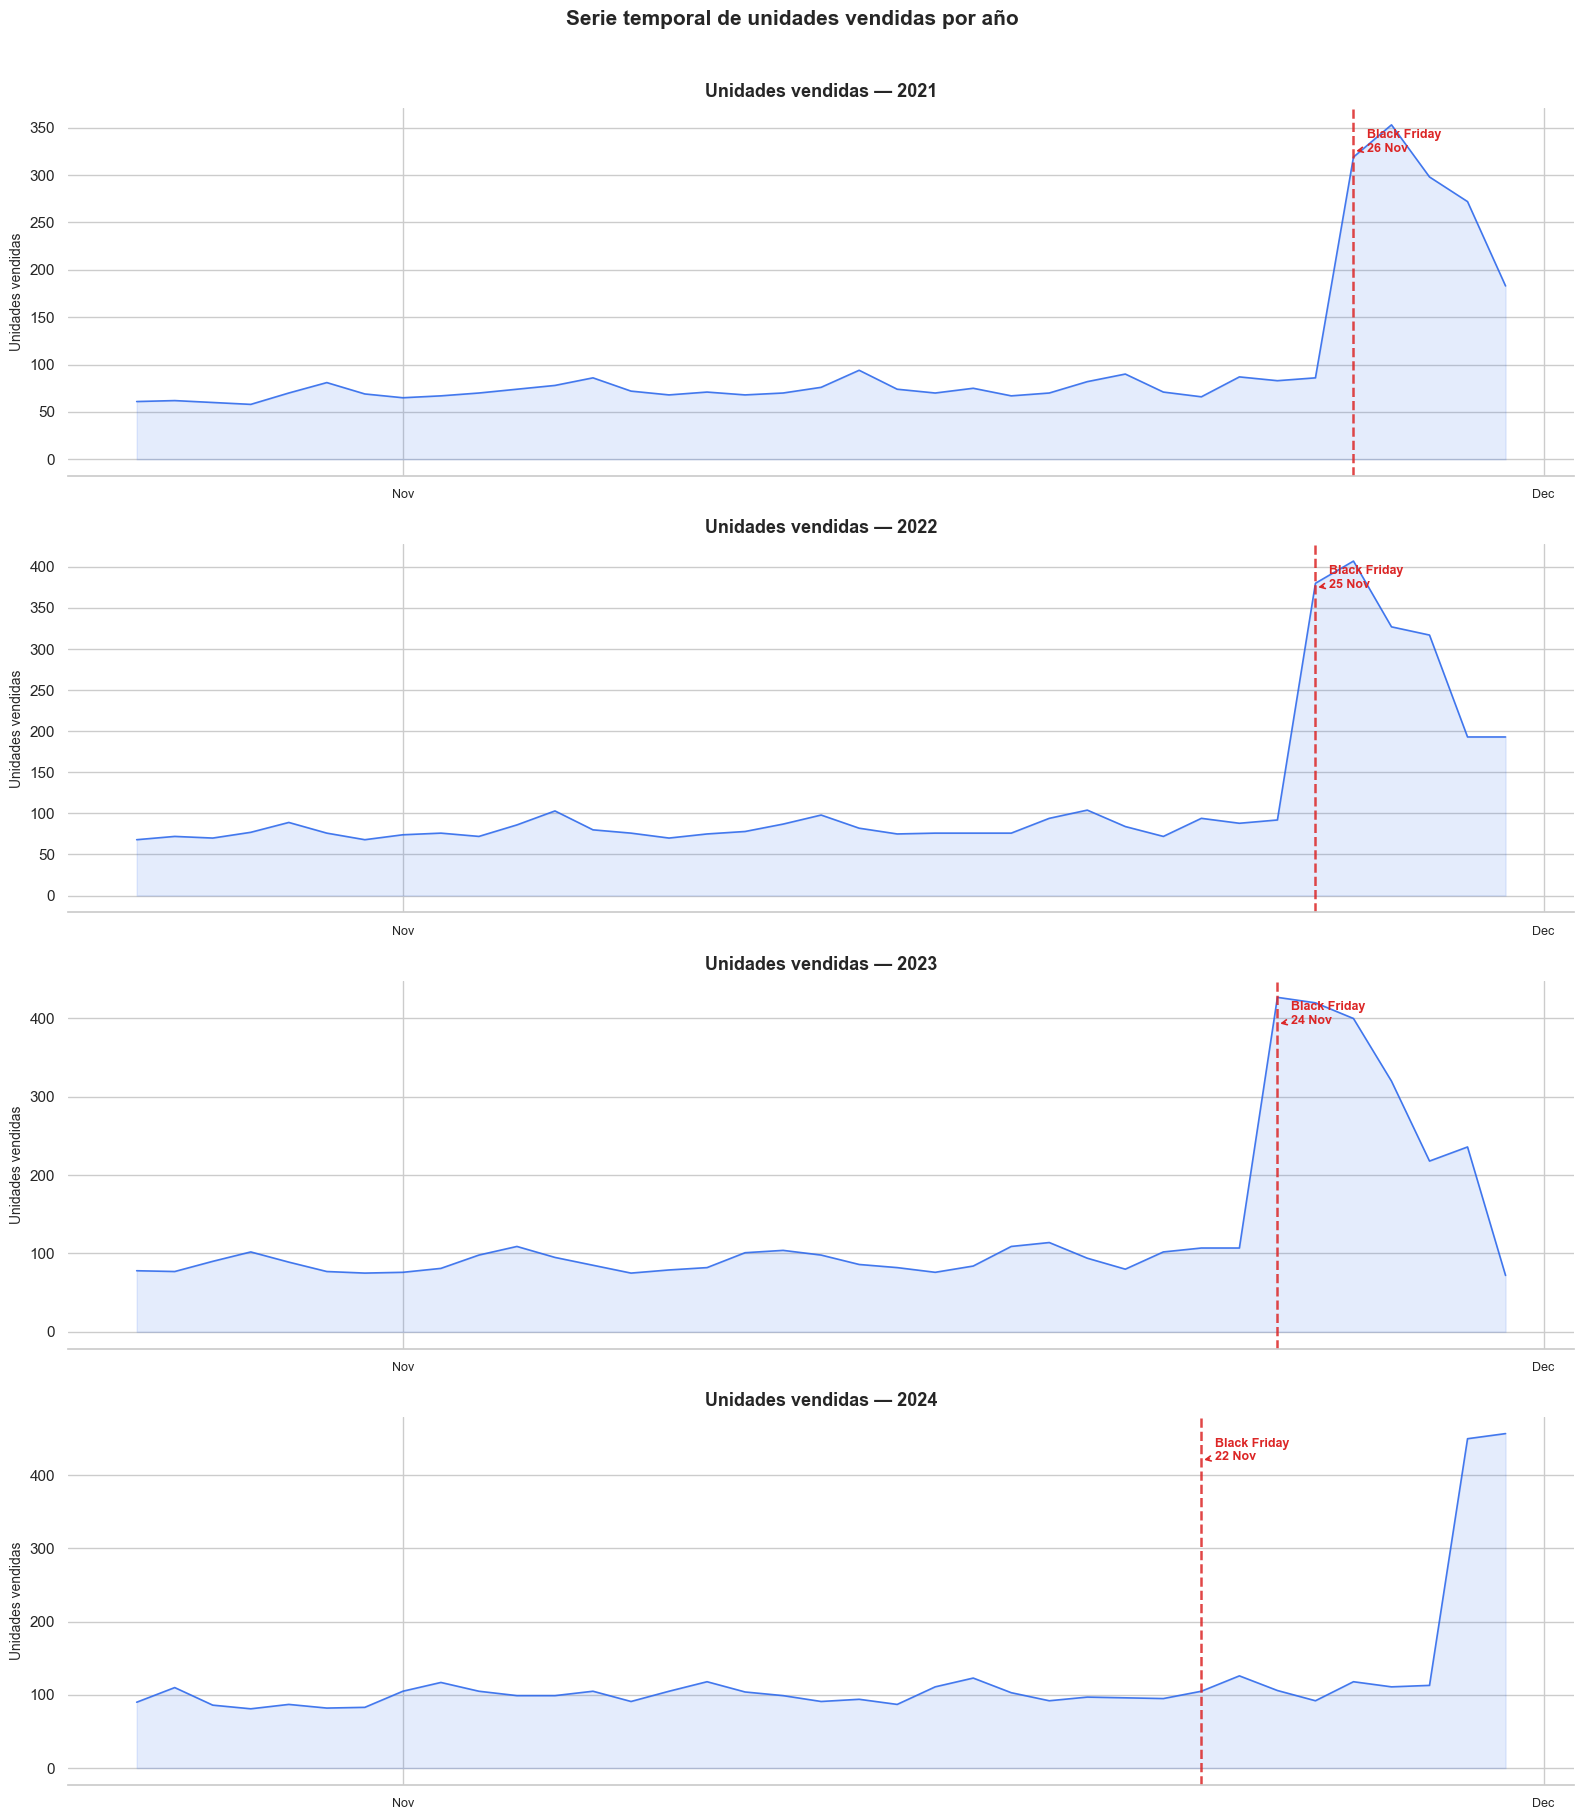

In [7]:

# ── Calcular Black Friday de cada año (4º viernes de noviembre) ──────────────
def black_friday(year):
    nov1 = pd.Timestamp(year=year, month=11, day=1)
    days_to_friday = (4 - nov1.dayofweek) % 7
    first_friday   = nov1 + pd.Timedelta(days=days_to_friday)
    return first_friday + pd.Timedelta(weeks=3)

# ── Serie diaria de unidades vendidas ────────────────────────────────────────
ventas_diarias = (
    df.groupby("fecha")["unidades_vendidas"]
    .sum()
    .reset_index()
    .sort_values("fecha")
)
ventas_diarias["año"] = ventas_diarias["fecha"].dt.year
años = sorted(ventas_diarias["año"].unique())

# ── Paleta y estilo ───────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
color_linea = "#2563EB"
color_bf    = "#DC2626"

fig, axes = plt.subplots(len(años), 1, figsize=(16, 4.5 * len(años)), sharex=False)
if len(años) == 1:
    axes = [axes]

for ax, año in zip(axes, años):
    datos_año = ventas_diarias[ventas_diarias["año"] == año]
    ax.plot(datos_año["fecha"], datos_año["unidades_vendidas"],
            color=color_linea, linewidth=1.2, alpha=0.85)
    ax.fill_between(datos_año["fecha"], datos_año["unidades_vendidas"],
                    alpha=0.12, color=color_linea)

    # Black Friday
    bf = black_friday(año)
    if datos_año["fecha"].min() <= bf <= datos_año["fecha"].max():
        bf_val = datos_año.loc[datos_año["fecha"] == bf, "unidades_vendidas"]
        ax.axvline(bf, color=color_bf, linewidth=1.8, linestyle="--", alpha=0.85)
        y_max = datos_año["unidades_vendidas"].max()
        ax.annotate(
            f"Black Friday\n{bf.strftime('%d %b')}",
            xy=(bf, y_max * 0.92),
            xytext=(10, 0), textcoords="offset points",
            color=color_bf, fontsize=9, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=color_bf, lw=1.2)
        )

    ax.set_title(f"Unidades vendidas — {año}", fontsize=13, fontweight="bold", pad=8)
    ax.set_xlabel("")
    ax.set_ylabel("Unidades vendidas", fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.tick_params(axis="x", labelsize=9)
    sns.despine(ax=ax, left=True)

plt.suptitle("Serie temporal de unidades vendidas por año", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


## 📆 Unidades vendidas por día de la semana

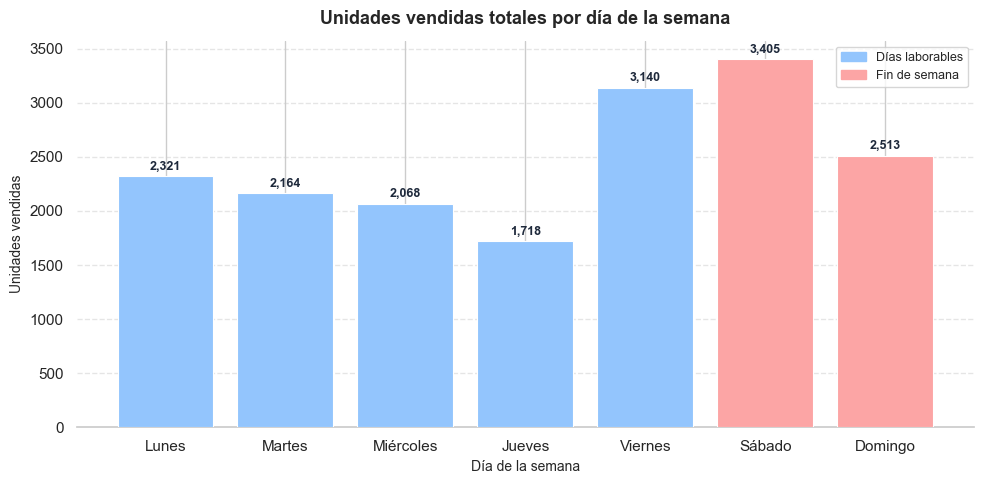

In [8]:

dias_semana = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

ventas_dia = (
    df.assign(dia_semana=df["fecha"].dt.dayofweek)
    .groupby("dia_semana")["unidades_vendidas"]
    .sum()
    .reindex(range(7))
    .reset_index()
)
ventas_dia["nombre_dia"] = dias_semana

fig, ax = plt.subplots(figsize=(10, 5))
colores = ["#93C5FD" if i < 5 else "#FCA5A5" for i in range(7)]
bars = ax.bar(ventas_dia["nombre_dia"], ventas_dia["unidades_vendidas"],
              color=colores, edgecolor="white", linewidth=0.8, zorder=3)

for bar, val in zip(bars, ventas_dia["unidades_vendidas"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + ventas_dia["unidades_vendidas"].max() * 0.01,
            f"{val:,.0f}", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1e293b")

ax.set_title("Unidades vendidas totales por día de la semana", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Día de la semana", fontsize=10)
ax.set_ylabel("Unidades vendidas", fontsize=10)
ax.yaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)
ax.set_axisbelow(True)

from matplotlib.patches import Patch
leyenda = [Patch(color="#93C5FD", label="Días laborables"), Patch(color="#FCA5A5", label="Fin de semana")]
ax.legend(handles=leyenda, fontsize=9, framealpha=0.8)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()


## 🏷️ Unidades vendidas por categoría

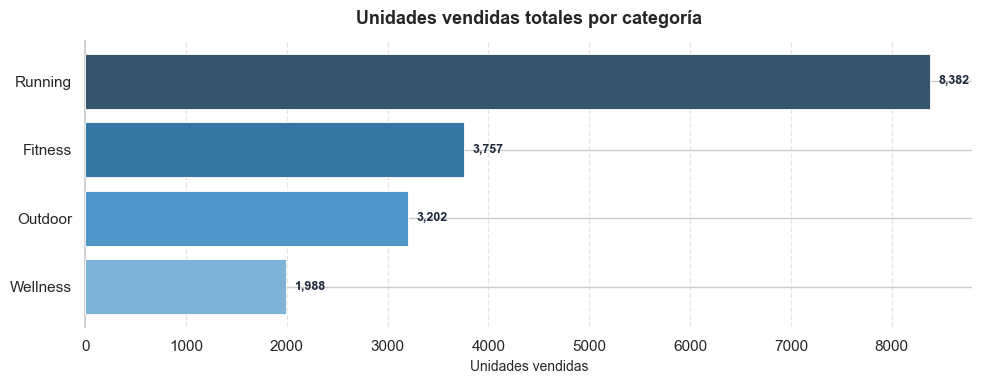

In [9]:

ventas_cat = (
    df.groupby("categoria")["unidades_vendidas"]
    .sum()
    .sort_values(ascending=True)
    .reset_index()
)

paleta_cat = sns.color_palette("Blues_d", len(ventas_cat))

fig, ax = plt.subplots(figsize=(10, max(4, len(ventas_cat) * 0.6)))
bars = ax.barh(ventas_cat["categoria"], ventas_cat["unidades_vendidas"],
               color=paleta_cat, edgecolor="white", linewidth=0.6, zorder=3)

for bar, val in zip(bars, ventas_cat["unidades_vendidas"]):
    ax.text(val + ventas_cat["unidades_vendidas"].max() * 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:,.0f}", va="center", fontsize=9, fontweight="bold", color="#1e293b")

ax.set_title("Unidades vendidas totales por categoría", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Unidades vendidas", fontsize=10)
ax.set_ylabel("")
ax.xaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)
ax.set_axisbelow(True)
sns.despine(ax=ax, bottom=True)
plt.tight_layout()
plt.show()


## 🗂️ Unidades vendidas por subcategoría

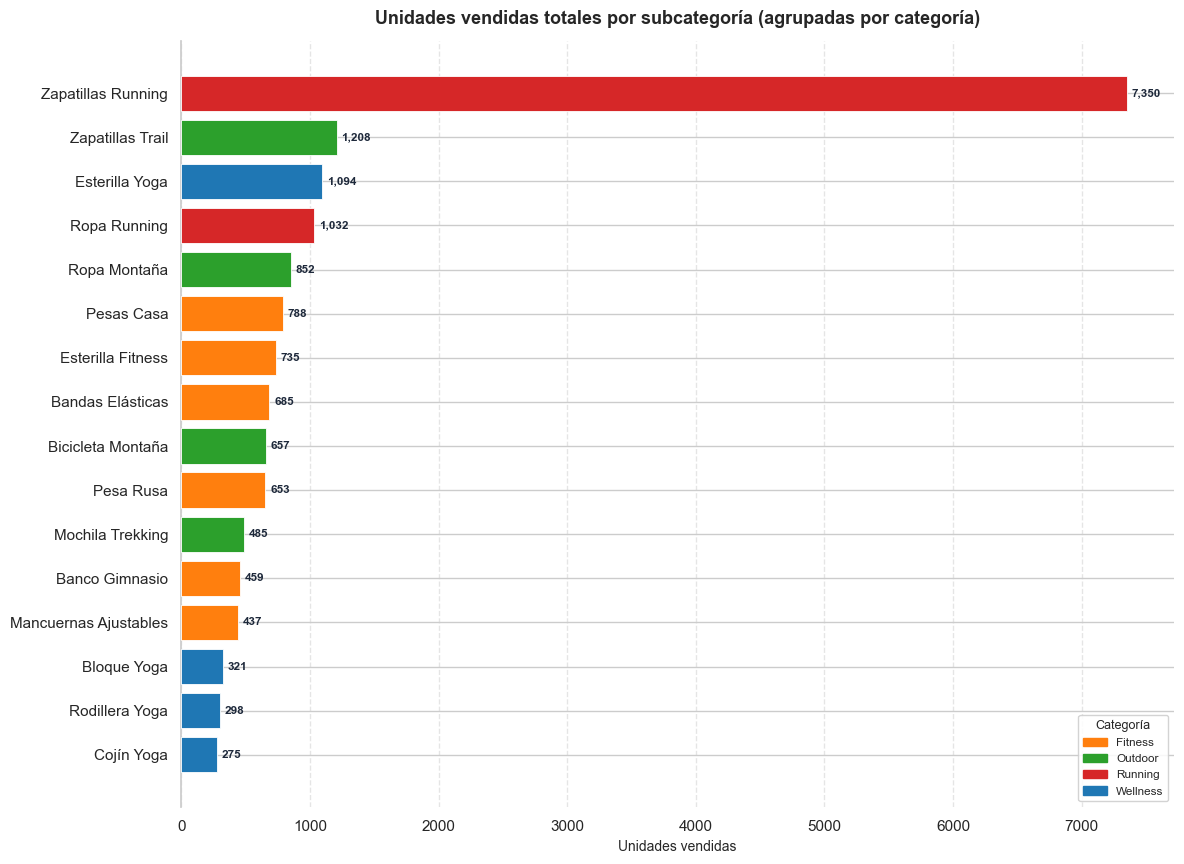

In [10]:

ventas_subcat = (
    df.groupby(["categoria", "subcategoria"])["unidades_vendidas"]
    .sum()
    .sort_values(ascending=True)
    .reset_index()
)

categorias_unicas = ventas_subcat["categoria"].unique()
paleta_por_cat = dict(zip(categorias_unicas, sns.color_palette("tab10", len(categorias_unicas))))
colores_subcat  = [paleta_por_cat[c] for c in ventas_subcat["categoria"]]

fig, ax = plt.subplots(figsize=(12, max(5, len(ventas_subcat) * 0.55)))
bars = ax.barh(ventas_subcat["subcategoria"], ventas_subcat["unidades_vendidas"],
               color=colores_subcat, edgecolor="white", linewidth=0.6, zorder=3)

for bar, val in zip(bars, ventas_subcat["unidades_vendidas"]):
    ax.text(val + ventas_subcat["unidades_vendidas"].max() * 0.005, bar.get_y() + bar.get_height() / 2,
            f"{val:,.0f}", va="center", fontsize=8.5, fontweight="bold", color="#1e293b")

from matplotlib.patches import Patch
leyenda_cat = [Patch(color=paleta_por_cat[c], label=c) for c in sorted(categorias_unicas)]
ax.legend(handles=leyenda_cat, title="Categoría", fontsize=8.5, title_fontsize=9,
          loc="lower right", framealpha=0.85)

ax.set_title("Unidades vendidas totales por subcategoría (agrupadas por categoría)",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Unidades vendidas", fontsize=10)
ax.set_ylabel("")
ax.xaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)
ax.set_axisbelow(True)
sns.despine(ax=ax, bottom=True)
plt.tight_layout()
plt.show()


## 🥇 Top productos por unidades vendidas

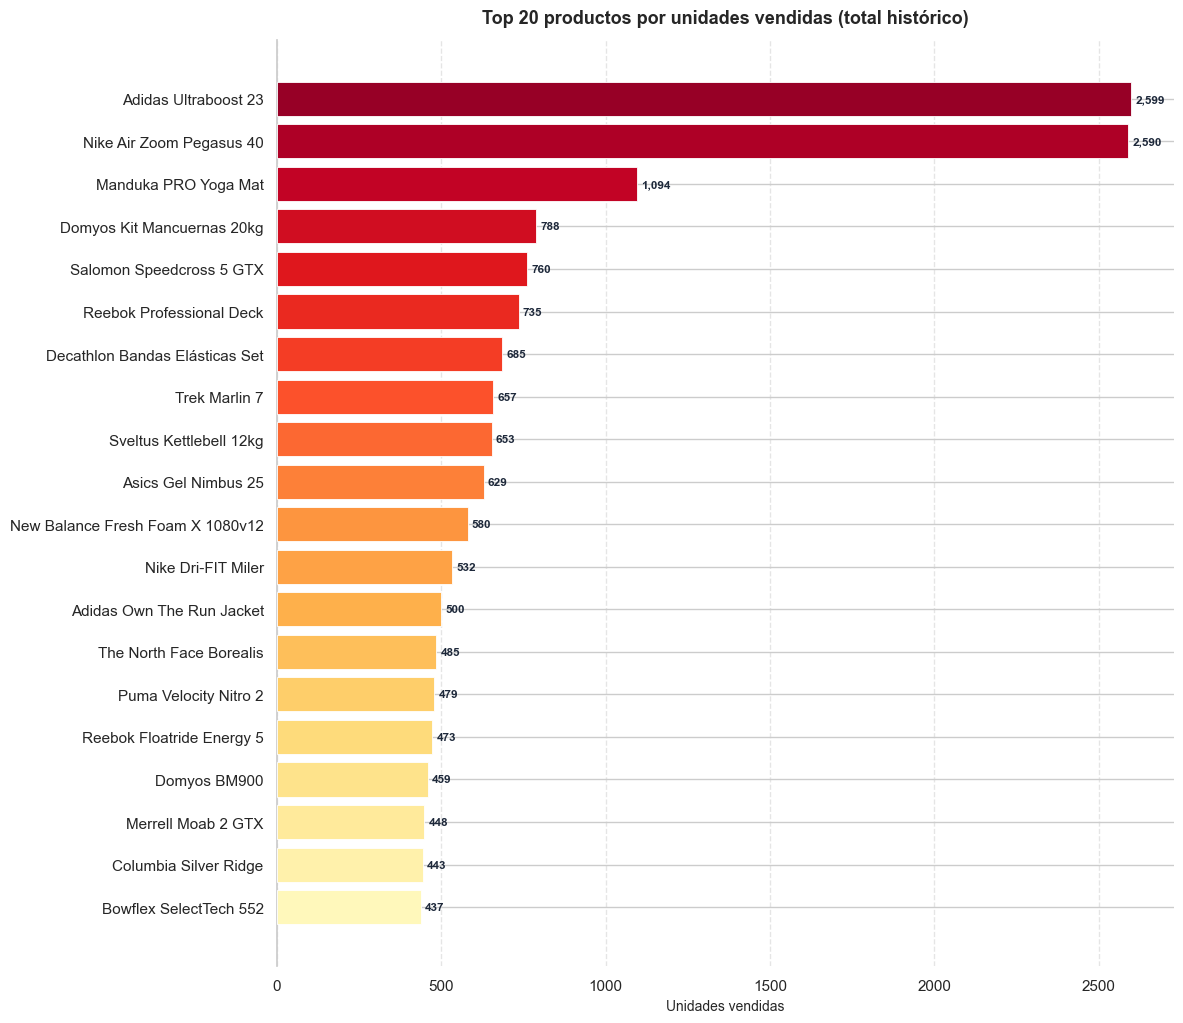

In [11]:

TOP_N = 20

top_productos = (
    df.groupby(["producto_id", "nombre"])["unidades_vendidas"]
    .sum()
    .sort_values(ascending=False)
    .head(TOP_N)
    .reset_index()
    .sort_values("unidades_vendidas", ascending=True)
)

# Gradiente de color según ranking
n = len(top_productos)
colores_top = sns.color_palette("YlOrRd", n)

fig, ax = plt.subplots(figsize=(12, max(6, n * 0.52)))
bars = ax.barh(top_productos["nombre"], top_productos["unidades_vendidas"],
               color=colores_top, edgecolor="white", linewidth=0.6, zorder=3)

max_val = top_productos["unidades_vendidas"].max()
for bar, val in zip(bars, top_productos["unidades_vendidas"]):
    ax.text(val + max_val * 0.005, bar.get_y() + bar.get_height() / 2,
            f"{val:,.0f}", va="center", fontsize=8.5, fontweight="bold", color="#1e293b")

ax.set_title(f"Top {TOP_N} productos por unidades vendidas (total histórico)",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Unidades vendidas", fontsize=10)
ax.set_ylabel("")
ax.xaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)
ax.set_axisbelow(True)
sns.despine(ax=ax, bottom=True)
plt.tight_layout()
plt.show()


## 💰 Distribución de densidad de precios: nuestros vs Amazon

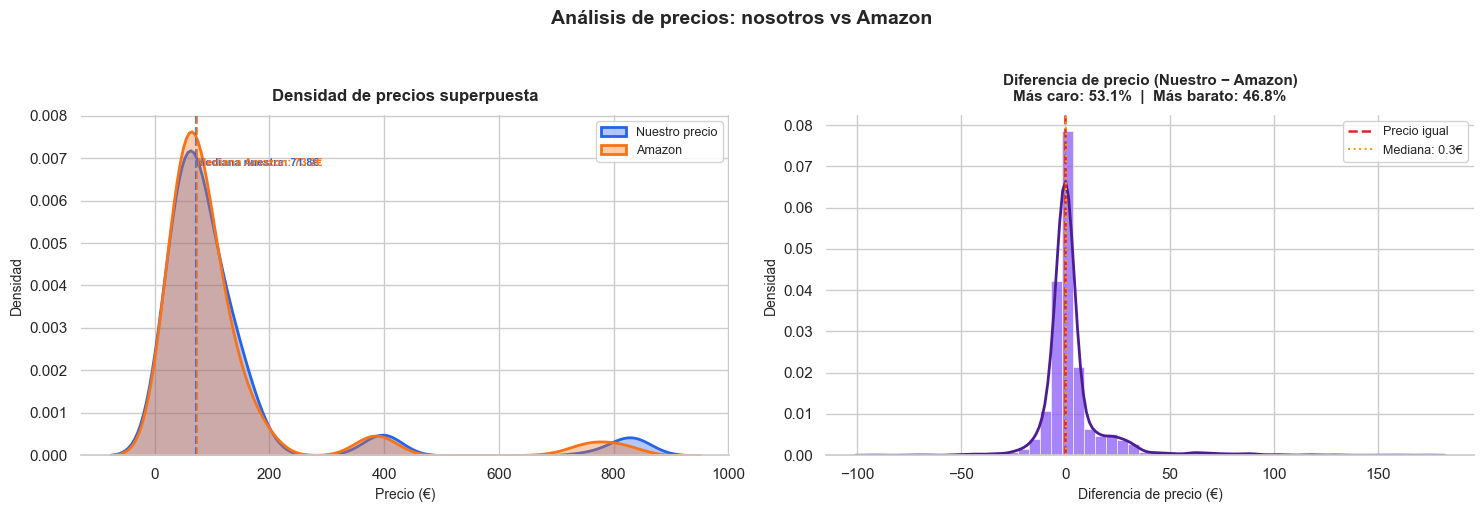


── Resumen de precios ──────────────────────────────────────────
       Nuestro precio   Amazon
count         3552.00  3552.00
mean           121.82   118.62
std            164.02   156.10
min             19.00    16.85
25%             47.21    47.12
50%             71.81    73.18
75%            118.22   114.34
max            854.22   858.35

Diferencia media  (Nuestro − Amazon): 3.19€
Diferencia mediana(Nuestro − Amazon): 0.33€


In [12]:

precios_nuestros = df["precio_venta"].dropna()
precios_amazon   = df["Amazon"].dropna()

color_nosotros = "#2563EB"
color_amazon   = "#F97316"

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ── Panel izquierdo: KDE superpuesto ─────────────────────────────────────────
ax = axes[0]
sns.kdeplot(precios_nuestros, ax=ax, fill=True, color=color_nosotros,
            alpha=0.35, linewidth=2, label="Nuestro precio")
sns.kdeplot(precios_amazon,   ax=ax, fill=True, color=color_amazon,
            alpha=0.35, linewidth=2, label="Amazon")

for precio, color, nombre in [
    (precios_nuestros.median(), color_nosotros, f"Mediana nuestra: {precios_nuestros.median():.1f}€"),
    (precios_amazon.median(),   color_amazon,   f"Mediana Amazon: {precios_amazon.median():.1f}€"),
]:
    ax.axvline(precio, color=color, linewidth=1.5, linestyle="--", alpha=0.8)
    ax.text(precio + 0.5, ax.get_ylim()[1] * 0.85 if ax.get_ylim()[1] > 0 else 0.005,
            nombre, color=color, fontsize=8, fontweight="bold")

ax.set_title("Densidad de precios superpuesta", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Precio (€)", fontsize=10)
ax.set_ylabel("Densidad", fontsize=10)
ax.legend(fontsize=9, framealpha=0.85)
sns.despine(ax=ax, left=True)

# ── Panel derecho: Diferencia de precio por producto (boxplot) ───────────────
ax = axes[1]
diferencia = df["precio_venta"] - df["Amazon"]
diferencia_limpia = diferencia.dropna()

sns.histplot(diferencia_limpia, ax=ax, bins=50, color="#8B5CF6",
             edgecolor="white", linewidth=0.4, stat="density", alpha=0.75)
sns.kdeplot(diferencia_limpia, ax=ax, color="#4C1D95", linewidth=2)

ax.axvline(0, color="#DC2626", linewidth=1.8, linestyle="--", label="Precio igual")
ax.axvline(diferencia_limpia.median(), color="#F59E0B", linewidth=1.5,
           linestyle=":", label=f"Mediana: {diferencia_limpia.median():.1f}€")

pct_mas_caro   = (diferencia_limpia > 0).mean() * 100
pct_mas_barato = (diferencia_limpia < 0).mean() * 100
ax.set_title(
    f"Diferencia de precio (Nuestro − Amazon)\n"
    f"Más caro: {pct_mas_caro:.1f}%  |  Más barato: {pct_mas_barato:.1f}%",
    fontsize=11, fontweight="bold", pad=10
)
ax.set_xlabel("Diferencia de precio (€)", fontsize=10)
ax.set_ylabel("Densidad", fontsize=10)
ax.legend(fontsize=9, framealpha=0.85)
sns.despine(ax=ax, left=True)

plt.suptitle("Análisis de precios: nosotros vs Amazon", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Resumen estadístico
print("\n── Resumen de precios ──────────────────────────────────────────")
resumen_precios = pd.DataFrame({
    "Nuestro precio": precios_nuestros.describe(),
    "Amazon":         precios_amazon.describe()
}).round(2)
print(resumen_precios.to_string())
print(f"\nDiferencia media  (Nuestro − Amazon): {diferencia_limpia.mean():.2f}€")
print(f"Diferencia mediana(Nuestro − Amazon): {diferencia_limpia.median():.2f}€")


# 🏗️ Ingeniería de Variables (Feature Engineering)

## 📅 Variables Temporales y de Calendario

In [13]:

# ============================================================
# INGENIERÍA DE VARIABLES — VARIABLES TEMPORALES Y CALENDARIO
# ============================================================

años_df     = df["fecha"].dt.year.unique().tolist()
festivos_es = holidays.Spain(years=años_df)

# ── Helpers para fechas móviles ───────────────────────────────────────────────
def black_friday(year):
    nov1         = pd.Timestamp(year=year, month=11, day=1)
    first_friday = nov1 + pd.Timedelta(days=(4 - nov1.dayofweek) % 7)
    return first_friday + pd.Timedelta(weeks=3)

def cyber_monday(year):
    return black_friday(year) + pd.Timedelta(days=3)

def primer_domingo_mayo(year):   # Día de la Madre en España
    may1 = pd.Timestamp(year=year, month=5, day=1)
    return may1 + pd.Timedelta(days=(6 - may1.dayofweek) % 7)

def pascua(year):
    # Algoritmo de Butcher para el Domingo de Pascua
    a = year % 19; b, c = divmod(year, 100); d, e = divmod(b, 4)
    f_ = (b + 8) // 25; g = (b - f_ + 1) // 3
    h  = (19*a + b - d - g + 15) % 30
    i, k = divmod(c, 4); l = (32 + 2*e + 2*i - h - k) % 7
    m    = (a + 11*h + 22*l) // 451
    month, day = divmod(114 + h + l - 7*m, 31)
    return pd.Timestamp(year=year, month=month, day=day + 1)

def _dias_hasta(fn, d):
    candidato = fn(d.year)
    if candidato < d:
        candidato = fn(d.year + 1)
    return (candidato - d).days

# Tablas de lookup por año
_bf  = {y: black_friday(y)                             for y in años_df}
_cm  = {y: cyber_monday(y)                             for y in años_df}
_dm  = {y: primer_domingo_mayo(y)                      for y in años_df}
_dp  = {y: pd.Timestamp(year=y, month=3, day=19)       for y in años_df}
_pac = {y: pascua(y)                                   for y in años_df}

f = df["fecha"]

# ── 1. Componentes básicas de fecha ──────────────────────────────────────────
df["año"]        = f.dt.year
df["mes"]        = f.dt.month
df["trimestre"]  = f.dt.quarter
df["semana_año"] = f.dt.isocalendar().week.astype(int)
df["dia_mes"]    = f.dt.day
df["dia_semana"] = f.dt.dayofweek   # 0 = Lunes … 6 = Domingo
df["dia_año"]    = f.dt.dayofyear

# ── 2. Etiquetas de texto ─────────────────────────────────────────────────────
_nom_dia = {0:"Lunes",1:"Martes",2:"Miércoles",3:"Jueves",
            4:"Viernes",5:"Sábado",6:"Domingo"}
_nom_mes = {1:"Enero",2:"Febrero",3:"Marzo",4:"Abril",5:"Mayo",6:"Junio",
            7:"Julio",8:"Agosto",9:"Septiembre",10:"Octubre",11:"Noviembre",12:"Diciembre"}
df["nombre_dia"] = f.dt.dayofweek.map(_nom_dia)
df["nombre_mes"] = f.dt.month.map(_nom_mes)

# ── 3. Temporada meteorológica ────────────────────────────────────────────────
_temp = {12:"Invierno",1:"Invierno",2:"Invierno",
          3:"Primavera",4:"Primavera",5:"Primavera",
          6:"Verano",  7:"Verano",  8:"Verano",
          9:"Otoño",  10:"Otoño",  11:"Otoño"}
df["temporada"] = f.dt.month.map(_temp)

# ── 4. Flags básicos ──────────────────────────────────────────────────────────
df["es_fin_semana"] = (f.dt.dayofweek >= 5).astype(int)
df["es_lunes"]      = (f.dt.dayofweek == 0).astype(int)
df["es_festivo"]    = f.map(lambda d: int(d in festivos_es))

# ── 5. Semana Santa (Domingo de Ramos → Domingo de Pascua) ───────────────────
df["es_semana_santa"] = f.map(
    lambda d: int(
        d.year in _pac and
        _pac[d.year] - pd.Timedelta(days=7) <= d <= _pac[d.year]
    )
)

# ── 6. Fechas comerciales especiales ─────────────────────────────────────────
df["es_black_friday"] = f.map(lambda d: int(d == _bf.get(d.year)))
df["es_cyber_monday"] = f.map(lambda d: int(d == _cm.get(d.year)))
df["es_dia_madre"]    = f.map(lambda d: int(d == _dm.get(d.year)))
df["es_dia_padre"]    = f.map(lambda d: int(d == _dp.get(d.year)))
df["es_navidad"]      = ((f.dt.month == 12) & (f.dt.day == 25)).astype(int)
df["es_nochebuena"]   = ((f.dt.month == 12) & (f.dt.day == 24)).astype(int)
df["es_nochevieja"]   = ((f.dt.month == 12) & (f.dt.day == 31)).astype(int)
df["es_reyes"]        = ((f.dt.month ==  1) & (f.dt.day ==  6)).astype(int)
df["es_san_valentin"] = ((f.dt.month ==  2) & (f.dt.day == 14)).astype(int)
df["es_halloween"]    = ((f.dt.month == 10) & (f.dt.day == 31)).astype(int)

# ── 7. Ventanas previas a grandes campañas (cuenta regresiva) ─────────────────
df["pre_black_friday"] = f.map(
    lambda d: int(1 <= (_bf.get(d.year) - d).days <= 7)
)
df["pre_navidad"] = ((f.dt.month == 12) & f.dt.day.between(18, 24)).astype(int)
df["pre_reyes"]   = ((f.dt.month ==  1) & f.dt.day.between(1,  5)).astype(int)

# ── 8. Posición dentro del mes ────────────────────────────────────────────────
df["es_inicio_mes"] = (f.dt.day <= 5).astype(int)
df["es_fin_mes"]    = (f.dt.day >= f.dt.days_in_month - 4).astype(int)

# ── 9. Distancia continua al próximo evento (en días) ────────────────────────
df["dias_para_black_friday"] = f.map(lambda d: _dias_hasta(black_friday, d))
df["dias_para_navidad"]      = f.map(
    lambda d: _dias_hasta(lambda y: pd.Timestamp(year=y, month=12, day=25), d)
)
df["dias_para_reyes"] = f.map(
    lambda d: _dias_hasta(lambda y: pd.Timestamp(year=y, month=1,  day=6),  d)
)

# ── 10. Codificación cíclica sin/cos — captura periodicidad para ML ───────────
df["mes_sin"]        = np.sin(2 * np.pi * f.dt.month     / 12)
df["mes_cos"]        = np.cos(2 * np.pi * f.dt.month     / 12)
df["dia_semana_sin"] = np.sin(2 * np.pi * f.dt.dayofweek / 7)
df["dia_semana_cos"] = np.cos(2 * np.pi * f.dt.dayofweek / 7)
df["dia_mes_sin"]    = np.sin(2 * np.pi * f.dt.day       / 31)
df["dia_mes_cos"]    = np.cos(2 * np.pi * f.dt.day       / 31)

# ── Resumen ───────────────────────────────────────────────────────────────────
cols_orig  = {"fecha","producto_id","unidades_vendidas","precio_venta",
              "categoria","subcategoria","nombre","Amazon","Decathlon","Deporvillage"}
nuevas_vars = [c for c in df.columns if c not in cols_orig]

grupos = {
    "Componentes de fecha" : ["año","mes","trimestre","semana_año","dia_mes","dia_semana","dia_año"],
    "Etiquetas"            : ["nombre_dia","nombre_mes","temporada"],
    "Flags básicos"        : ["es_fin_semana","es_lunes","es_festivo","es_semana_santa"],
    "Eventos comerciales"  : ["es_black_friday","es_cyber_monday","es_dia_madre","es_dia_padre",
                               "es_navidad","es_nochebuena","es_nochevieja","es_reyes",
                               "es_san_valentin","es_halloween"],
    "Ventanas previas"     : ["pre_black_friday","pre_navidad","pre_reyes"],
    "Posición en mes"      : ["es_inicio_mes","es_fin_mes"],
    "Distancia a eventos"  : ["dias_para_black_friday","dias_para_navidad","dias_para_reyes"],
    "Cíclicas (sin/cos)"   : ["mes_sin","mes_cos","dia_semana_sin","dia_semana_cos",
                               "dia_mes_sin","dia_mes_cos"],
}

print(f"Variables temporales creadas: {len(nuevas_vars)}\n")
for grupo, cols in grupos.items():
    print(f"  [{grupo}]")
    print("    " + ", ".join(cols))

df[["fecha"] + nuevas_vars[:8]].drop_duplicates(subset="fecha").sort_values("fecha").head(10)


Variables temporales creadas: 41

  [Componentes de fecha]
    año, mes, trimestre, semana_año, dia_mes, dia_semana, dia_año
  [Etiquetas]
    nombre_dia, nombre_mes, temporada
  [Flags básicos]
    es_fin_semana, es_lunes, es_festivo, es_semana_santa
  [Eventos comerciales]
    es_black_friday, es_cyber_monday, es_dia_madre, es_dia_padre, es_navidad, es_nochebuena, es_nochevieja, es_reyes, es_san_valentin, es_halloween
  [Ventanas previas]
    pre_black_friday, pre_navidad, pre_reyes
  [Posición en mes]
    es_inicio_mes, es_fin_mes
  [Distancia a eventos]
    dias_para_black_friday, dias_para_navidad, dias_para_reyes
  [Cíclicas (sin/cos)]
    mes_sin, mes_cos, dia_semana_sin, dia_semana_cos, dia_mes_sin, dia_mes_cos


,fecha,precio_base,es_estrella,ingresos,año,mes,trimestre,semana_año,dia_mes
0,2021-10-25,115,True,710.16,2021,10,4,43,25
24,2021-10-26,115,True,938.96,2021,10,4,43,26
48,2021-10-27,115,True,914.16,2021,10,4,43,27
72,2021-10-28,115,True,826.98,2021,10,4,43,28
96,2021-10-29,115,True,1406.76,2021,10,4,43,29
120,2021-10-30,115,True,1420.92,2021,10,4,43,30
144,2021-10-31,115,True,1016.91,2021,10,4,43,31
168,2021-11-01,115,True,805.49,2021,11,4,44,1
192,2021-11-02,115,True,1161.00,2021,11,4,44,2
216,2021-11-03,115,True,1260.38,2021,11,4,44,3


## ⏳ Lags de unidades vendidas y media móvil

In [14]:

# ============================================================
# INGENIERÍA DE VARIABLES — LAGS Y MEDIA MÓVIL
# ============================================================
# Se agrupa por (producto_id, año) para no mezclar los últimos
# registros de noviembre de un año con los primeros de octubre
# del siguiente.

df = df.sort_values(["producto_id", "año", "fecha"]).reset_index(drop=True)

# Lags lag_1 a lag_7
for i in range(1, 8):
    df[f"lag_{i}"] = (
        df.groupby(["producto_id", "año"])["unidades_vendidas"]
        .shift(i)
    )

# Media móvil de los 7 días anteriores (sin incluir el día actual)
df["media_movil_7"] = (
    df.groupby(["producto_id", "año"])["unidades_vendidas"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=7).mean())
)

lag_cols        = [f"lag_{i}" for i in range(1, 8)]
media_movil_col = "media_movil_7"
nuevas_cols     = lag_cols + [media_movil_col]

filas_antes   = len(df)
df = df.dropna(subset=nuevas_cols).reset_index(drop=True)
filas_despues = len(df)

print(f"Nuevas variables creadas : {nuevas_cols}")
print(f"\nFilas antes de eliminar nulos : {filas_antes:,}")
print(f"Filas eliminadas              : {filas_antes - filas_despues:,}")
print(f"Filas después                 : {filas_despues:,}")
print(f"\nVerificación de nulos en variables nuevas:")
print(df[nuevas_cols].isnull().sum())

df[["fecha", "producto_id", "año", "unidades_vendidas"] + nuevas_cols].head(10)


Nuevas variables creadas : ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'media_movil_7']

Filas antes de eliminar nulos : 3,552
Filas eliminadas              : 672
Filas después                 : 2,880

Verificación de nulos en variables nuevas:
lag_1            0
lag_2            0
lag_3            0
lag_4            0
lag_5            0
lag_6            0
lag_7            0
media_movil_7    0
dtype: int64


,fecha,producto_id,año,unidades_vendidas,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,media_movil_7
0,2021-11-01,PROD_001,2021,7,9.0,12.0,12.0,7.0,8.0,8.0,6.0,8.857143
1,2021-11-02,PROD_001,2021,10,7.0,9.0,12.0,12.0,7.0,8.0,8.0,9.000000
2,2021-11-03,PROD_001,2021,11,10.0,7.0,9.0,12.0,12.0,7.0,8.0,9.285714
3,2021-11-04,PROD_001,2021,12,11.0,10.0,7.0,9.0,12.0,12.0,7.0,9.714286
4,2021-11-05,PROD_001,2021,10,12.0,11.0,10.0,7.0,9.0,12.0,12.0,10.428571
5,2021-11-06,PROD_001,2021,10,10.0,12.0,11.0,10.0,7.0,9.0,12.0,10.142857
6,2021-11-07,PROD_001,2021,10,10.0,10.0,12.0,11.0,10.0,7.0,9.0,9.857143
7,2021-11-08,PROD_001,2021,9,10.0,10.0,10.0,12.0,11.0,10.0,7.0,10.000000
8,2021-11-09,PROD_001,2021,11,9.0,10.0,10.0,10.0,12.0,11.0,10.0,10.285714
9,2021-11-10,PROD_001,2021,10,11.0,9.0,10.0,10.0,10.0,12.0,11.0,10.428571


## 🏷️ Variable de Descuento

In [15]:
df["descuento_porcentaje"] = (df["precio_venta"] - df["precio_base"]) / df["precio_base"] * 100

print(f"descuento_porcentaje — estadísticos:")
print(df["descuento_porcentaje"].describe().round(2))
df[["fecha", "producto_id", "precio_base", "precio_venta", "descuento_porcentaje"]].head(10)

descuento_porcentaje — estadísticos:
count    2880.00
mean       -1.35
std         3.81
min       -15.00
25%        -2.33
50%        -0.55
75%         1.26
max         2.99
Name: descuento_porcentaje, dtype: float64


,fecha,producto_id,precio_base,precio_venta,descuento_porcentaje
0,2021-11-01,PROD_001,115,115.07,0.060870
1,2021-11-02,PROD_001,115,116.10,0.956522
2,2021-11-03,PROD_001,115,114.58,-0.365217
3,2021-11-04,PROD_001,115,112.23,-2.408696
4,2021-11-05,PROD_001,115,113.81,-1.034783
5,2021-11-06,PROD_001,115,117.80,2.434783
6,2021-11-07,PROD_001,115,116.04,0.904348
7,2021-11-08,PROD_001,115,113.46,-1.339130
8,2021-11-09,PROD_001,115,113.98,-0.886957
9,2021-11-10,PROD_001,115,117.57,2.234783


## 🏪 Variables de Competencia

In [16]:
df["precio_competencia"] = df[["Amazon", "Decathlon", "Deporvillage"]].mean(axis=1)
df["ratio_precio"]       = df["precio_venta"] / df["precio_competencia"]

df.drop(columns=["Amazon", "Decathlon", "Deporvillage"], inplace=True)

print(f"precio_competencia — estadísticos:")
print(df["precio_competencia"].describe().round(2))
print(f"\nratio_precio — estadísticos:")
print(df["ratio_precio"].describe().round(4))
print(f"\nColumnas eliminadas: Amazon, Decathlon, Deporvillage")
df[["fecha", "producto_id", "precio_venta", "precio_competencia", "ratio_precio"]].head(10)

precio_competencia — estadísticos:
count    2880.00
mean      116.26
std       154.87
min        16.65
25%        45.56
50%        70.19
75%       110.67
max       884.62
Name: precio_competencia, dtype: float64

ratio_precio — estadísticos:
count    2880.0000
mean        1.0335
std         0.0596
min         0.8231
25%         1.0001
50%         1.0304
75%         1.0612
max         1.3030
Name: ratio_precio, dtype: float64

Columnas eliminadas: Amazon, Decathlon, Deporvillage


,fecha,producto_id,precio_venta,precio_competencia,ratio_precio
0,2021-11-01,PROD_001,115.07,95.353333,1.206775
1,2021-11-02,PROD_001,116.10,96.153333,1.207446
2,2021-11-03,PROD_001,114.58,95.240000,1.203066
3,2021-11-04,PROD_001,112.23,96.590000,1.161922
4,2021-11-05,PROD_001,113.81,96.170000,1.183425
5,2021-11-06,PROD_001,117.80,95.436667,1.234326
6,2021-11-07,PROD_001,116.04,96.153333,1.206822
7,2021-11-08,PROD_001,113.46,97.003333,1.169651
8,2021-11-09,PROD_001,113.98,96.933333,1.175860
9,2021-11-10,PROD_001,117.57,96.343333,1.220323


## 🔢 One-Hot Encoding de Variables Categóricas

In [17]:
cols_cat = ["nombre", "categoria", "subcategoria"]
for col in cols_cat:
    df[f"{col}_h"] = df[col]

ohe_cols = [f"{col}_h" for col in cols_cat]
df = pd.get_dummies(df, columns=ohe_cols, drop_first=False, dtype=int)

nuevas_ohe = [c for c in df.columns if any(c.startswith(f"{col}_h_") for col in cols_cat)]
print(f"Columnas OHE generadas: {len(nuevas_ohe)}")
for col in cols_cat:
    cols_grupo = [c for c in df.columns if c.startswith(f"{col}_h_")]
    print(f"  {col}_h → {len(cols_grupo)} columnas: {cols_grupo}")

print(f"\nShape del dataframe: {df.shape}")

Columnas OHE generadas: 44
  nombre_h → 24 columnas: ['nombre_h_Adidas Own The Run Jacket', 'nombre_h_Adidas Ultraboost 23', 'nombre_h_Asics Gel Nimbus 25', 'nombre_h_Bowflex SelectTech 552', 'nombre_h_Columbia Silver Ridge', 'nombre_h_Decathlon Bandas Elásticas Set', 'nombre_h_Domyos BM900', 'nombre_h_Domyos Kit Mancuernas 20kg', 'nombre_h_Gaiam Premium Yoga Block', 'nombre_h_Liforme Yoga Pad', 'nombre_h_Lotuscrafts Yoga Bolster', 'nombre_h_Manduka PRO Yoga Mat', 'nombre_h_Merrell Moab 2 GTX', 'nombre_h_New Balance Fresh Foam X 1080v12', 'nombre_h_Nike Air Zoom Pegasus 40', 'nombre_h_Nike Dri-FIT Miler', 'nombre_h_Puma Velocity Nitro 2', 'nombre_h_Quechua MH500', 'nombre_h_Reebok Floatride Energy 5', 'nombre_h_Reebok Professional Deck', 'nombre_h_Salomon Speedcross 5 GTX', 'nombre_h_Sveltus Kettlebell 12kg', 'nombre_h_The North Face Borealis', 'nombre_h_Trek Marlin 7']
  categoria_h → 4 columnas: ['categoria_h_Fitness', 'categoria_h_Outdoor', 'categoria_h_Running', 'categoria_h_Wellne

## 💾 Guardado del Dataset Procesado

In [18]:
output_path = "../data/processed/df.csv"
df.to_csv(output_path, index=False)
print(f"Dataset guardado en: {output_path}")
print(f"Shape: {df.shape}")

Dataset guardado en: ../data/processed/df.csv
Shape: (2880, 103)


# ✂️ División Train / Validation

In [19]:

train_df      = df[df["año"].between(2021, 2023)].reset_index(drop=True)
validation_df = df[df["año"] == 2024].reset_index(drop=True)

print(f"train_df      (2021–2023): {len(train_df):,} registros")
print(f"validation_df (2024)     : {len(validation_df):,} registros")
print(f"Total                    : {len(train_df) + len(validation_df):,} registros")


train_df      (2021–2023): 2,160 registros
validation_df (2024)     : 720 registros
Total                    : 2,880 registros


# 🤖 Modelado — HistGradientBoostingRegressor

In [20]:

# ============================================================
# SELECCIÓN DE FEATURES
# ============================================================

EXCLUIR = {"fecha", "ingresos", "unidades_vendidas"}

cols_no_numericas = set(
    train_df.select_dtypes(include=["object", "string", "category"]).columns
)

feature_cols = [
    c for c in train_df.columns
    if c not in EXCLUIR and c not in cols_no_numericas
]

X_train = train_df[feature_cols]
y_train = train_df["unidades_vendidas"]

X_val = validation_df[feature_cols]
y_val = validation_df["unidades_vendidas"]

print(f"Features utilizadas : {len(feature_cols)}")
print(", ".join(feature_cols))
print(f"\nX_train : {X_train.shape}  |  y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape}  |  y_val   : {y_val.shape}")


Features utilizadas : 93
precio_base, es_estrella, precio_venta, año, mes, trimestre, semana_año, dia_mes, dia_semana, dia_año, es_fin_semana, es_lunes, es_festivo, es_semana_santa, es_black_friday, es_cyber_monday, es_dia_madre, es_dia_padre, es_navidad, es_nochebuena, es_nochevieja, es_reyes, es_san_valentin, es_halloween, pre_black_friday, pre_navidad, pre_reyes, es_inicio_mes, es_fin_mes, dias_para_black_friday, dias_para_navidad, dias_para_reyes, mes_sin, mes_cos, dia_semana_sin, dia_semana_cos, dia_mes_sin, dia_mes_cos, lag_1, lag_2, lag_3, lag_4, lag_5, lag_6, lag_7, media_movil_7, descuento_porcentaje, precio_competencia, ratio_precio, nombre_h_Adidas Own The Run Jacket, nombre_h_Adidas Ultraboost 23, nombre_h_Asics Gel Nimbus 25, nombre_h_Bowflex SelectTech 552, nombre_h_Columbia Silver Ridge, nombre_h_Decathlon Bandas Elásticas Set, nombre_h_Domyos BM900, nombre_h_Domyos Kit Mancuernas 20kg, nombre_h_Gaiam Premium Yoga Block, nombre_h_Liforme Yoga Pad, nombre_h_Lotuscrafts Yo

In [21]:

# ============================================================
# ENTRENAMIENTO — HistGradientBoostingRegressor
# ============================================================

model = sklearn.ensemble.HistGradientBoostingRegressor(
    learning_rate     = 0.05,   # bajo → actualización lenta, menos overfitting
    max_iter          = 500,    # suficientes árboles para converger
    max_depth         = 4,      # profundidad moderada
    min_samples_leaf  = 20,     # regularización por hoja
    l2_regularization = 1.0,    # penalización L2
    max_leaf_nodes    = 31,
    early_stopping    = False,
    random_state      = 42,
)

model.fit(X_train, y_train)
print("Entrenamiento completado.")
print(f"  Iteraciones realizadas : {model.n_iter_}")


Entrenamiento completado.
  Iteraciones realizadas : 500


In [22]:

# ============================================================
# MÉTRICAS DE FORECASTING — MODELO vs BASELINE NAIVE
# ============================================================

y_pred_train = model.predict(X_train)
y_pred_val   = model.predict(X_val)

# Baseline: predice siempre la media de train
baseline_val = np.full(len(y_val), y_train.mean())

def calcular_metricas(y_true, y_pred, nombre):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    mae  = sklearn.metrics.mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(sklearn.metrics.mean_squared_error(y_true, y_pred))
    # Evita divisiones por cero usando clip(1)
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(y_true, 1, None))) * 100
    r2   = sklearn.metrics.r2_score(y_true, y_pred)
    return {"Modelo": nombre, "MAE": round(mae, 3), "RMSE": round(rmse, 3),
            "MAPE (%)": round(mape, 2), "R²": round(r2, 4)}

resultados = pd.DataFrame([
    calcular_metricas(y_train, y_pred_train, "HGBR — Train"),
    calcular_metricas(y_val,   y_pred_val,   "HGBR — Validation"),
    calcular_metricas(y_val,   baseline_val, "Baseline naive (media)"),
])

print("═" * 65)
print("  MÉTRICAS DE FORECASTING")
print("═" * 65)
print(resultados.to_string(index=False))
print("═" * 65)

# ── Mejora relativa del modelo sobre el baseline ──────────────────────────────
for metrica in ["MAE", "RMSE", "MAPE (%)"]:
    val_modelo   = resultados.loc[resultados["Modelo"] == "HGBR — Validation", metrica].values[0]
    val_baseline = resultados.loc[resultados["Modelo"] == "Baseline naive (media)", metrica].values[0]
    mejora_pct   = (val_baseline - val_modelo) / val_baseline * 100
    print(f"  Mejora {metrica:<10}: {mejora_pct:+.1f}%  vs baseline")


═════════════════════════════════════════════════════════════════
  MÉTRICAS DE FORECASTING
═════════════════════════════════════════════════════════════════
                Modelo   MAE  RMSE  MAPE (%)      R²
          HGBR — Train 0.600 0.992     14.89  0.9790
     HGBR — Validation 1.253 2.400     25.48  0.8714
Baseline naive (media) 3.669 6.692     93.02 -0.0001
═════════════════════════════════════════════════════════════════
  Mejora MAE       : +65.8%  vs baseline
  Mejora RMSE      : +64.1%  vs baseline
  Mejora MAPE (%)  : +72.6%  vs baseline


# ⭐ Predicción vs Realidad — Productos Estrella — Noviembre 2024

Productos estrella en noviembre 2024 : 7
Registros totales                    : 210
  · Adidas Ultraboost 23  (30 días)
  · Bowflex SelectTech 552  (30 días)
  · Domyos BM900  (30 días)
  · Manduka PRO Yoga Mat  (30 días)
  · Nike Air Zoom Pegasus 40  (30 días)
  · Salomon Speedcross 5 GTX  (30 días)
  · Trek Marlin 7  (30 días)


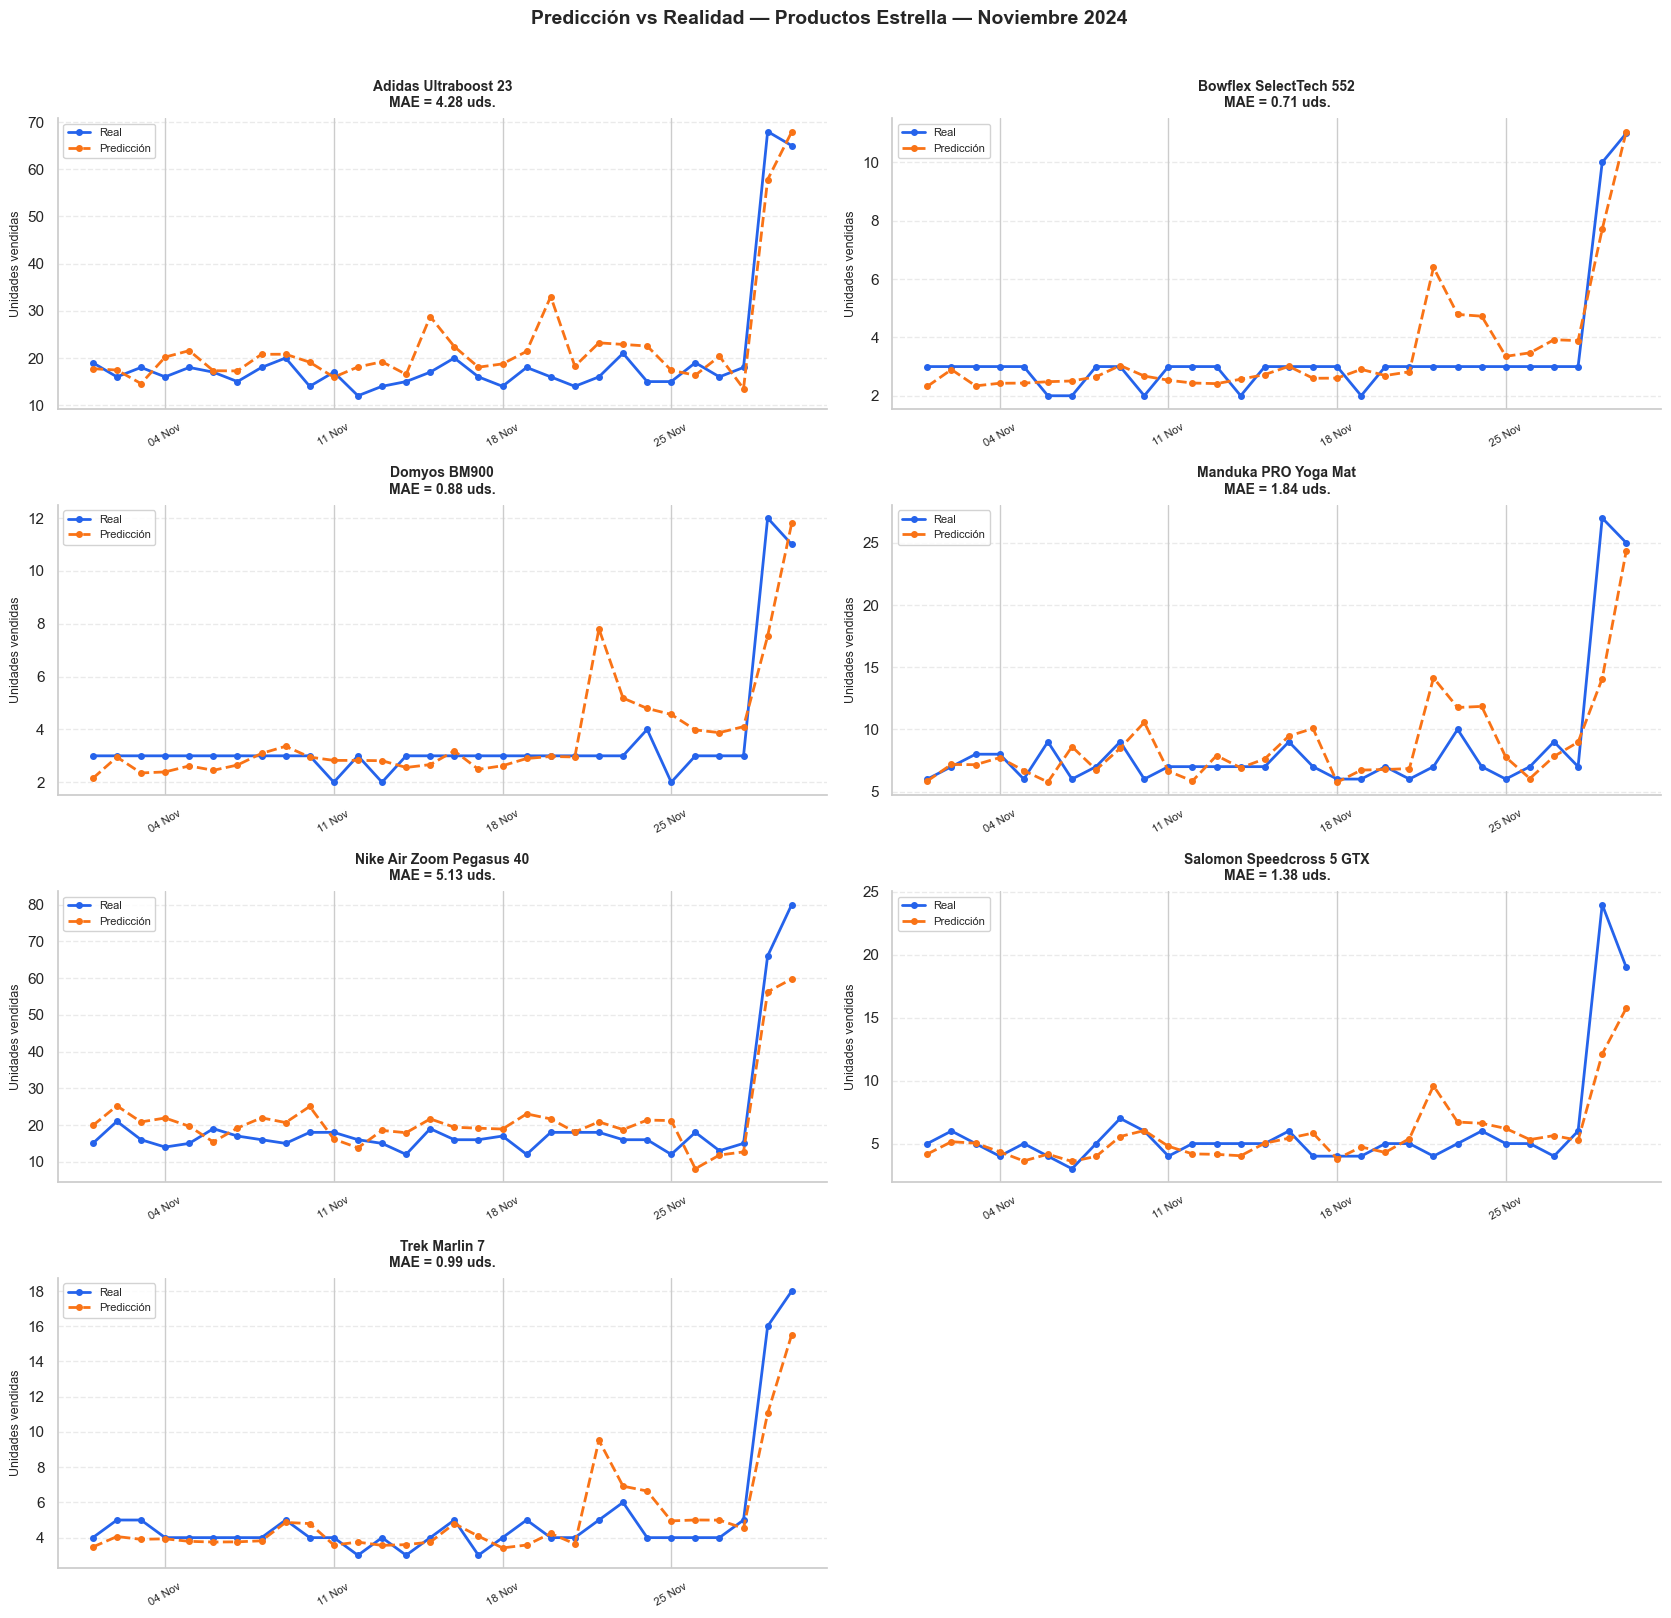

In [23]:

# ============================================================
# PREDICCIÓN — PRODUCTOS ESTRELLA — NOVIEMBRE 2024
# ============================================================

nov_estrellas = validation_df[
    (validation_df["mes"] == 11) &
    (validation_df["es_estrella"] == True)
].copy()

nov_estrellas["prediccion"] = model.predict(nov_estrellas[feature_cols])

productos = sorted(nov_estrellas["nombre"].unique())
print(f"Productos estrella en noviembre 2024 : {len(productos)}")
print(f"Registros totales                    : {len(nov_estrellas)}")
for p in productos:
    n_dias = nov_estrellas[nov_estrellas["nombre"] == p]["fecha"].nunique()
    print(f"  · {p}  ({n_dias} días)")

# ── Gráficos ─────────────────────────────────────────────────────────────────
COLOR_REAL = "#2563EB"
COLOR_PRED = "#F97316"

ncols = 2
nrows = (len(productos) + 1) // 2

fig, axes = plt.subplots(nrows, ncols, figsize=(17, nrows * 4), sharex=False)
axes_flat = axes.flatten()

for i, nombre_prod in enumerate(productos):
    ax   = axes_flat[i]
    dato = nov_estrellas[nov_estrellas["nombre"] == nombre_prod].sort_values("fecha")

    ax.plot(dato["fecha"], dato["unidades_vendidas"],
            color=COLOR_REAL, linewidth=2, marker="o", markersize=4,
            label="Real")
    ax.plot(dato["fecha"], dato["prediccion"],
            color=COLOR_PRED, linewidth=2, marker="o", markersize=4,
            linestyle="--", label="Predicción")

    mae_prod = np.mean(np.abs(dato["unidades_vendidas"] - dato["prediccion"]))
    ax.set_title(f"{nombre_prod}\nMAE = {mae_prod:.2f} uds.", fontsize=10, fontweight="bold", pad=8)
    ax.set_ylabel("Unidades vendidas", fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1))
    ax.tick_params(axis="x", labelsize=8, rotation=30)
    ax.legend(fontsize=8, framealpha=0.85)
    ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

# Ocultar ejes sobrantes si el número de productos es impar
for j in range(len(productos), len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle(
    "Predicción vs Realidad — Productos Estrella — Noviembre 2024",
    fontsize=14, fontweight="bold", y=1.01
)
plt.tight_layout()
plt.show()


In [24]:

mae_por_producto = (
    nov_estrellas
    .assign(error_abs=lambda x: np.abs(x["unidades_vendidas"] - x["prediccion"]))
    .groupby("nombre")["error_abs"]
    .mean()
    .rename("MAE")
    .sort_values()
    .reset_index()
)
mae_por_producto["MAE"] = mae_por_producto["MAE"].round(3)

print("MAE por producto estrella — Noviembre 2024")
print("─" * 55)
print(mae_por_producto.to_string(index=False))
print("─" * 55)
print(f"MAE medio global : {mae_por_producto['MAE'].mean():.3f}")


MAE por producto estrella — Noviembre 2024
───────────────────────────────────────────────────────
                  nombre   MAE
  Bowflex SelectTech 552 0.706
            Domyos BM900 0.879
           Trek Marlin 7 0.990
Salomon Speedcross 5 GTX 1.383
    Manduka PRO Yoga Mat 1.839
    Adidas Ultraboost 23 4.280
Nike Air Zoom Pegasus 40 5.130
───────────────────────────────────────────────────────
MAE medio global : 2.172


# 📉 Degradación del error por periodo — Noviembre 2024

Métricas por periodo — productos estrella agregados
──────────────────────────────────────────────────────────
      periodo   MAE  RMSE  MAPE (%)     R²
 P1: 1–10 nov 1.558 2.462     17.30 0.8257
P2: 11–20 nov 1.775 3.367     20.02 0.6359
P3: 21–30 nov 3.184 4.819     33.74 0.9032

MAE por periodo × producto
──────────────────────────────────────────────────────────
nombre         Adidas Ultraboost 23  Bowflex SelectTech 552  Domyos BM900  Manduka PRO Yoga Mat  Nike Air Zoom Pegasus 40  Salomon Speedcross 5 GTX  Trek Marlin 7
periodo                                                                                                                                                           
P1: 1–10 nov                  2.514                   0.463         0.394                 1.330                     5.097                     0.667          0.445
P2: 11–20 nov                 5.532                   0.447         0.379                 0.787                     3.926                    

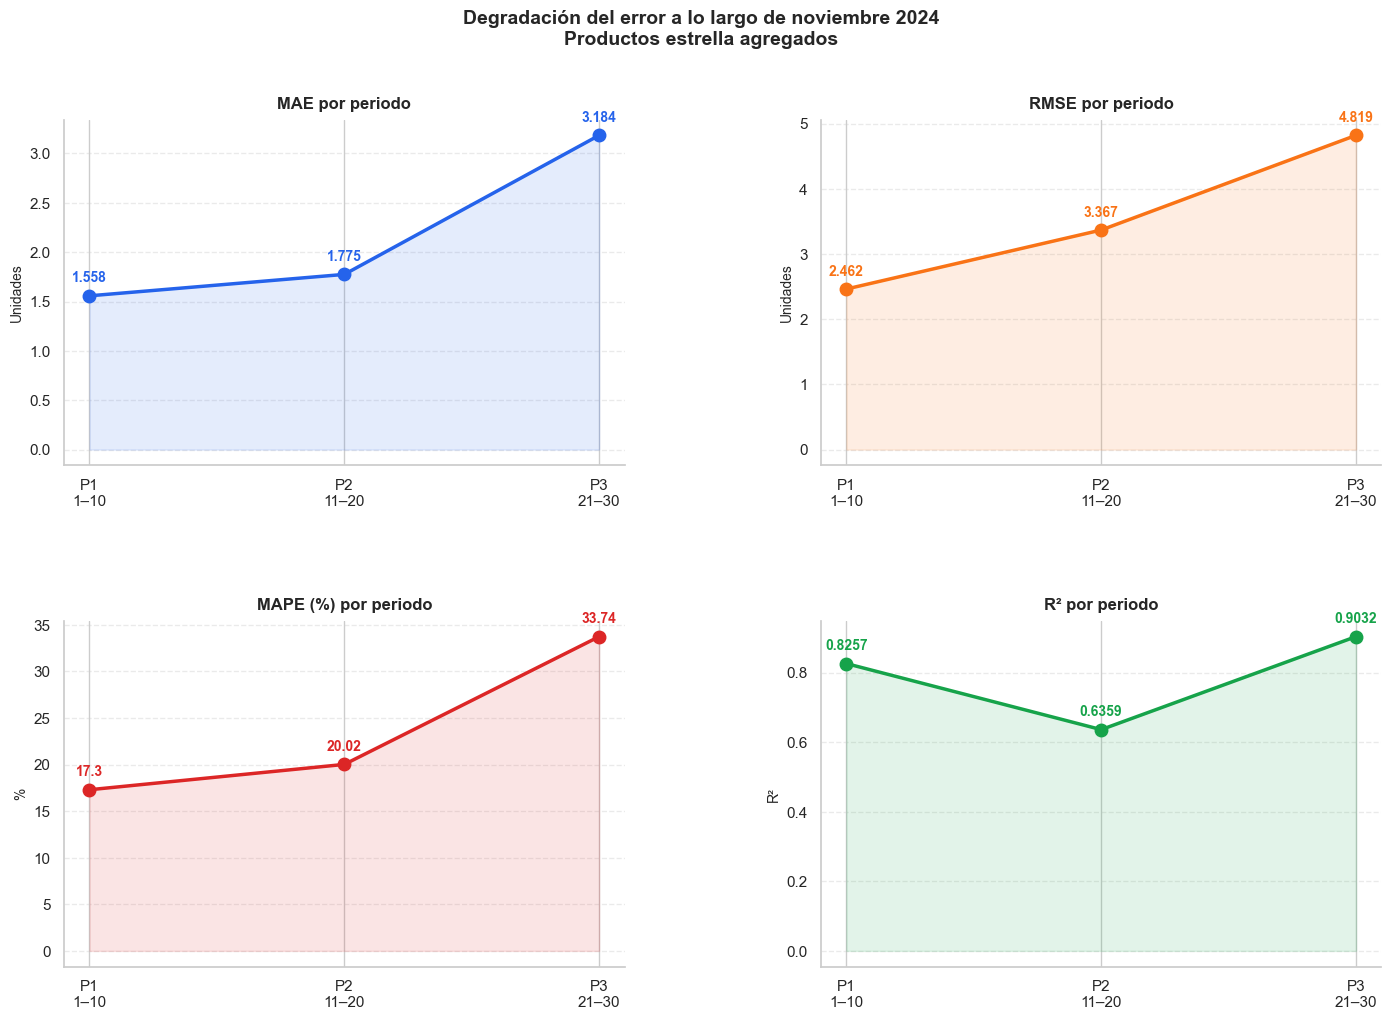

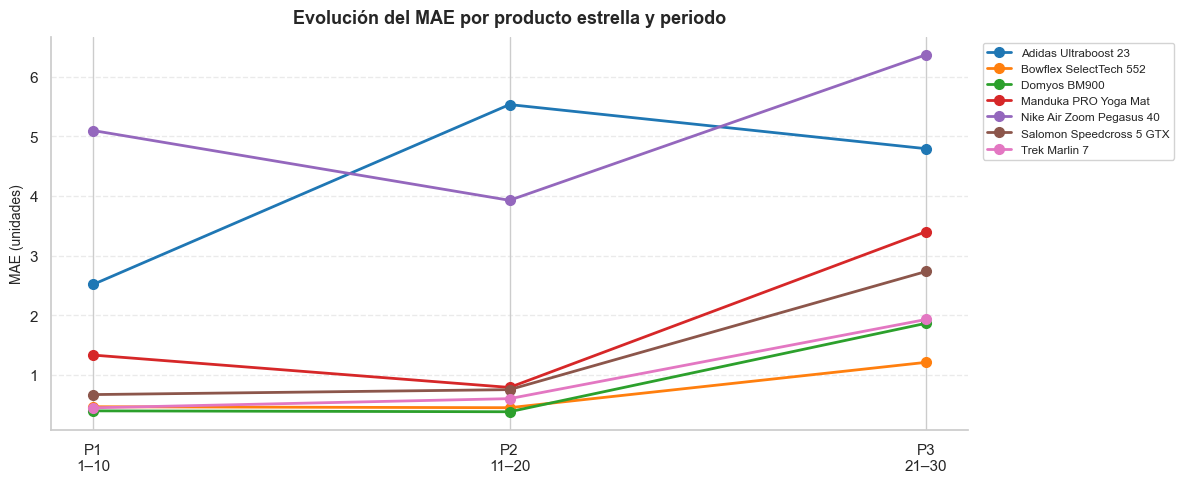

In [25]:

# ============================================================
# DEGRADACIÓN DEL ERROR POR PERIODO — NOVIEMBRE 2024
# ============================================================

# ── 1. Asignar periodo ────────────────────────────────────────────────────────
def asignar_periodo(dia):
    if dia <= 10:  return "P1: 1–10 nov"
    if dia <= 20:  return "P2: 11–20 nov"
    return             "P3: 21–30 nov"

nov = nov_estrellas.copy()
nov["periodo"] = nov["dia_mes"].map(asignar_periodo)
periodos_orden = ["P1: 1–10 nov", "P2: 11–20 nov", "P3: 21–30 nov"]

# ── 2. Métricas agregadas por periodo (todos los productos estrella) ──────────
def metricas_periodo(grp):
    y_true = grp["unidades_vendidas"]
    y_pred = grp["prediccion"]
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(y_true, 1, None))) * 100
    r2   = sklearn.metrics.r2_score(y_true, y_pred)
    return pd.Series({"MAE": round(mae, 3), "RMSE": round(rmse, 3),
                      "MAPE (%)": round(mape, 2), "R²": round(r2, 4)})

metricas_df = (
    nov.groupby("periodo", sort=False)
    .apply(metricas_periodo)
    .reindex(periodos_orden)
    .reset_index()
)

print("Métricas por periodo — productos estrella agregados")
print("─" * 58)
print(metricas_df.to_string(index=False))

# ── 3. MAE por periodo × producto ────────────────────────────────────────────
mae_pxp = (
    nov.assign(error_abs=lambda x: np.abs(x["unidades_vendidas"] - x["prediccion"]))
    .groupby(["periodo", "nombre"])["error_abs"]
    .mean()
    .round(3)
    .unstack("nombre")
    .reindex(periodos_orden)
)
print("\nMAE por periodo × producto")
print("─" * 58)
print(mae_pxp.to_string())

# ── 4. Gráficos ───────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(17, 11))
gs  = fig.add_gridspec(2, 2, hspace=0.45, wspace=0.35)

ax_mae  = fig.add_subplot(gs[0, 0])
ax_rmse = fig.add_subplot(gs[0, 1])
ax_mape = fig.add_subplot(gs[1, 0])
ax_r2   = fig.add_subplot(gs[1, 1])

etiquetas_cortas = ["P1\n1–10", "P2\n11–20", "P3\n21–30"]
AZUL = "#2563EB";  NARANJA = "#F97316";  ROJO = "#DC2626";  VERDE = "#16A34A"

def plot_metrica(ax, col, color, titulo, ylabel, invertir=False):
    vals = metricas_df[col].values
    ax.plot(etiquetas_cortas, vals, color=color, linewidth=2.5,
            marker="o", markersize=9, zorder=3)
    ax.fill_between(etiquetas_cortas, vals, alpha=0.12, color=color)
    for x, y in zip(etiquetas_cortas, vals):
        ax.annotate(f"{y}", xy=(x, y), xytext=(0, 10),
                    textcoords="offset points", ha="center",
                    fontsize=10, fontweight="bold", color=color)
    if invertir:   # R²: flecha hacia arriba es buena
        ax.invert_yaxis()
    ax.set_title(titulo, fontsize=12, fontweight="bold", pad=8)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.yaxis.grid(True, linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

plot_metrica(ax_mae,  "MAE",      AZUL,    "MAE por periodo",      "Unidades")
plot_metrica(ax_rmse, "RMSE",     NARANJA, "RMSE por periodo",     "Unidades")
plot_metrica(ax_mape, "MAPE (%)", ROJO,    "MAPE (%) por periodo", "%")
plot_metrica(ax_r2,   "R²",       VERDE,   "R² por periodo",       "R²")

plt.suptitle(
    "Degradación del error a lo largo de noviembre 2024\n"
    "Productos estrella agregados",
    fontsize=14, fontweight="bold"
)
plt.show()

# ── 5. Gráfico de líneas MAE por producto y periodo ───────────────────────────
fig2, ax = plt.subplots(figsize=(12, 5))

paleta = sns.color_palette("tab10", len(mae_pxp.columns))
for col, color in zip(mae_pxp.columns, paleta):
    ax.plot(etiquetas_cortas, mae_pxp[col].values,
            marker="o", linewidth=2, markersize=7,
            label=col, color=color)

ax.set_title("Evolución del MAE por producto estrella y periodo",
             fontsize=13, fontweight="bold", pad=10)
ax.set_ylabel("MAE (unidades)", fontsize=10)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(fontsize=8.5, framealpha=0.85, bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


# 🛍️ Análisis Black Friday 2024 — Todos los productos

Black Friday 2024 : Friday 22 de November de 2024
Productos en Black Friday : 24

producto_id                           nombre  es_estrella  unidades_vendidas  prediccion  error_abs
   PROD_001         Nike Air Zoom Pegasus 40         True                 18       20.86       2.86
   PROD_002             Adidas Ultraboost 23         True                 16       23.21       7.21
   PROD_003              Asics Gel Nimbus 25        False                  3        8.57       5.57
   PROD_004 New Balance Fresh Foam X 1080v12        False                  4        6.30       2.30
   PROD_005               Nike Dri-FIT Miler        False                  3        8.31       5.31
   PROD_006        Adidas Own The Run Jacket        False                  3        6.71       3.71
   PROD_007            Puma Velocity Nitro 2        False                  3        6.42       3.42
   PROD_008        Reebok Floatride Energy 5        False                  3        6.34       3.34
   PROD_009       

C:\Users\User\AppData\Local\Temp\ipykernel_22568\1792024158.py:69: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\User\anaconda3\envs\forecastingventas\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


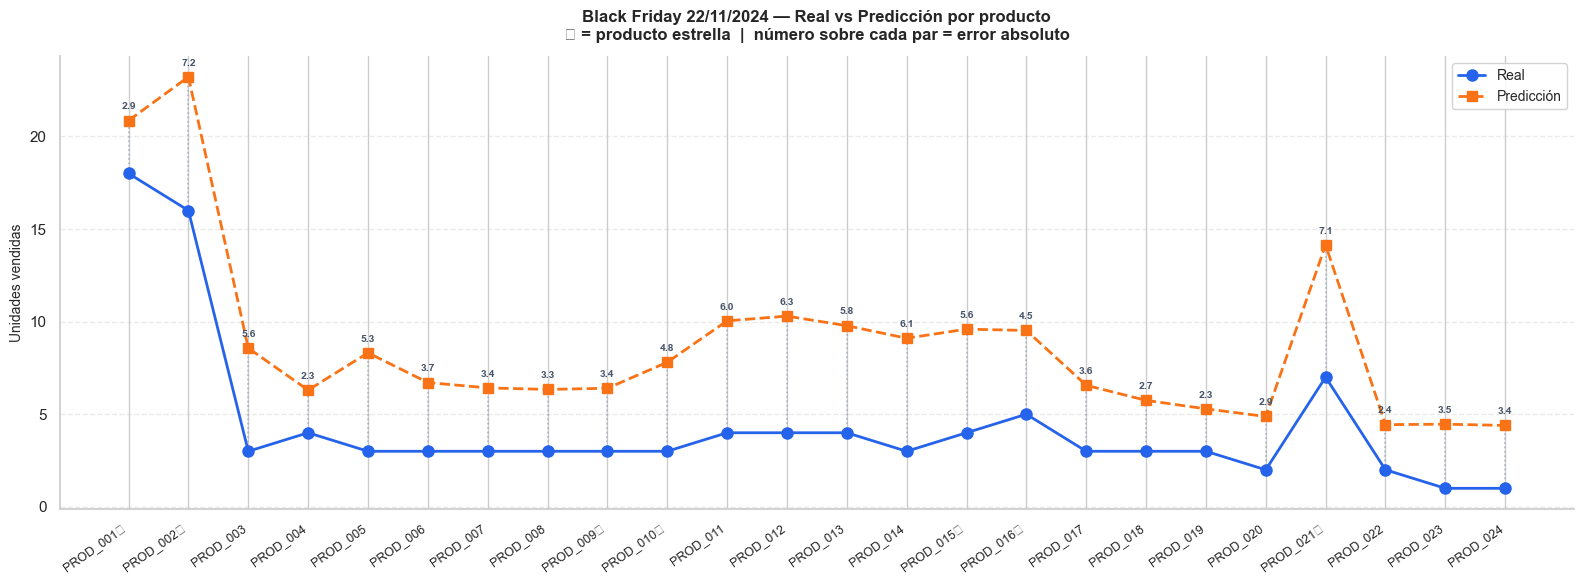

In [26]:

# ============================================================
# BLACK FRIDAY 2024 — REAL vs PREDICHO — TODOS LOS PRODUCTOS
# ============================================================

fecha_bf = black_friday(2024)
print(f"Black Friday 2024 : {fecha_bf.strftime('%A %d de %B de %Y')}")

# ── 1. Filtrar y predecir ─────────────────────────────────────────────────────
bf_df = validation_df[validation_df["fecha"] == fecha_bf].copy()
bf_df["prediccion"] = model.predict(bf_df[feature_cols])
bf_df = bf_df.sort_values("producto_id").reset_index(drop=True)

print(f"Productos en Black Friday : {len(bf_df)}")
print()

# Tabla resumen
resumen_bf = bf_df[["producto_id", "nombre", "es_estrella",
                     "unidades_vendidas", "prediccion"]].copy()
resumen_bf["error_abs"] = np.abs(resumen_bf["unidades_vendidas"] - resumen_bf["prediccion"]).round(2)
resumen_bf["prediccion"] = resumen_bf["prediccion"].round(2)
print(resumen_bf.to_string(index=False))
print(f"\nMAE Black Friday (todos los productos) : {resumen_bf['error_abs'].mean():.3f}")

# ── 2. Gráfico real vs predicho ───────────────────────────────────────────────
# Etiquetas del eje X: ID + asterisco si es estrella
etiquetas_x = [
    f"{row.producto_id}{'★' if row.es_estrella else ''}"
    for row in bf_df.itertuples()
]

COLOR_REAL = "#2563EB"
COLOR_PRED = "#F97316"
COLOR_ERR  = "#94A3B8"

fig, ax = plt.subplots(figsize=(16, 6))

x = np.arange(len(bf_df))

# Líneas de conexión real–predicho por producto (error visual)
for xi, real, pred in zip(x, bf_df["unidades_vendidas"], bf_df["prediccion"]):
    ax.plot([xi, xi], [real, pred], color=COLOR_ERR, linewidth=1.2,
            linestyle=":", zorder=1, alpha=0.7)

# Líneas y puntos
ax.plot(x, bf_df["unidades_vendidas"], color=COLOR_REAL, linewidth=2,
        marker="o", markersize=8, label="Real", zorder=3)
ax.plot(x, bf_df["prediccion"],        color=COLOR_PRED, linewidth=2,
        marker="s", markersize=7, linestyle="--", label="Predicción", zorder=3)

# Anotar error absoluto encima de cada par
for xi, real, pred in zip(x, bf_df["unidades_vendidas"], bf_df["prediccion"]):
    err = abs(real - pred)
    ypos = max(real, pred) + 0.5
    ax.text(xi, ypos, f"{err:.1f}", ha="center", va="bottom",
            fontsize=7.5, color="#475569", fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(etiquetas_x, fontsize=9, rotation=35, ha="right")
ax.set_ylabel("Unidades vendidas", fontsize=10)
ax.set_title(
    f"Black Friday {fecha_bf.strftime('%d/%m/%Y')} — Real vs Predicción por producto\n"
    "★ = producto estrella  |  número sobre cada par = error absoluto",
    fontsize=12, fontweight="bold", pad=12
)
ax.legend(fontsize=10, framealpha=0.85)
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


# 🔁 Modelo Final — Reentrenamiento con todos los datos (2021–2024)

In [27]:

# ============================================================
# MODELO FINAL — ENTRENAMIENTO CON DF COMPLETO (2021–2024)
# ============================================================

# ── 1. Preparar features sobre el df completo ─────────────────────────────────
# Se reutilizan exactamente las mismas feature_cols del modelo anterior
X_full = df[feature_cols]
y_full = df["unidades_vendidas"]

print(f"Rango temporal     : {df['fecha'].min().date()}  →  {df['fecha'].max().date()}")
print(f"Registros totales  : {len(df):,}")
print(f"Features utilizadas: {len(feature_cols)}")

# ── 2. Entrenar modelo final con los mismos hiperparámetros ───────────────────
model_final = sklearn.ensemble.HistGradientBoostingRegressor(
    learning_rate     = 0.05,
    max_iter          = 500,
    max_depth         = 4,
    min_samples_leaf  = 20,
    l2_regularization = 1.0,
    max_leaf_nodes    = 31,
    early_stopping    = False,
    random_state      = 42,
)

model_final.fit(X_full, y_full)

# ── 3. Métricas in-sample (referencia, no es validación real) ─────────────────
y_pred_full = model_final.predict(X_full)
mae_full    = sklearn.metrics.mean_absolute_error(y_full, y_pred_full)
rmse_full   = np.sqrt(sklearn.metrics.mean_squared_error(y_full, y_pred_full))
mape_full   = np.mean(np.abs((y_full - y_pred_full) / np.clip(y_full, 1, None))) * 100
r2_full     = sklearn.metrics.r2_score(y_full, y_pred_full)

print(f"\nEntrenamiento completado — iteraciones: {model_final.n_iter_}")
print()
print("Métricas in-sample (2021–2024)   ← referencia, no validación")
print("─" * 50)
print(f"  MAE      : {mae_full:.3f}")
print(f"  RMSE     : {rmse_full:.3f}")
print(f"  MAPE (%) : {mape_full:.2f}")
print(f"  R²       : {r2_full:.4f}")
print()

# ── 4. Comparativa rápida con el modelo de validación ─────────────────────────
print("Comparativa: modelo validación (2021–2023) vs modelo final (2021–2024)")
print("─" * 68)
print(f"{'':30} {'Val. model (val set)':>22}  {'Final (in-sample)':>18}")
print(f"  {'MAE':<28} {resumen_bf['error_abs'].mean():>22.3f}  {mae_full:>18.3f}")
print()
print("model_final listo para predicción futura.")


Rango temporal     : 2021-11-01  →  2024-11-30
Registros totales  : 2,880
Features utilizadas: 93

Entrenamiento completado — iteraciones: 500

Métricas in-sample (2021–2024)   ← referencia, no validación
──────────────────────────────────────────────────
  MAE      : 0.601
  RMSE     : 0.959
  MAPE (%) : 15.10
  R²       : 0.9802

Comparativa: modelo validación (2021–2023) vs modelo final (2021–2024)
────────────────────────────────────────────────────────────────────
                                 Val. model (val set)   Final (in-sample)
  MAE                                           4.341               0.601

model_final listo para predicción futura.


# 📊 Importancia de Variables — Permutation Importance

Calculando permutation importance… (puede tardar unos segundos)

Top 30 variables por permutation importance (de 93 totales)
───────────────────────────────────────────────────────
                            feature  importancia      std
               descuento_porcentaje     1.350600 0.036455
                              lag_7     0.906288 0.018500
                              lag_1     0.808410 0.005789
                      media_movil_7     0.476285 0.011355
                       ratio_precio     0.172591 0.016124
                              lag_6     0.158194 0.008440
                         dia_semana     0.074092 0.006615
                     dia_semana_sin     0.070199 0.005471
                     dia_semana_cos     0.064325 0.006964
             dias_para_black_friday     0.043586 0.003877
                              lag_3     0.042006 0.002926
                            dia_mes     0.033207 0.002530
                              lag_5     0.029117 0.001796
      n

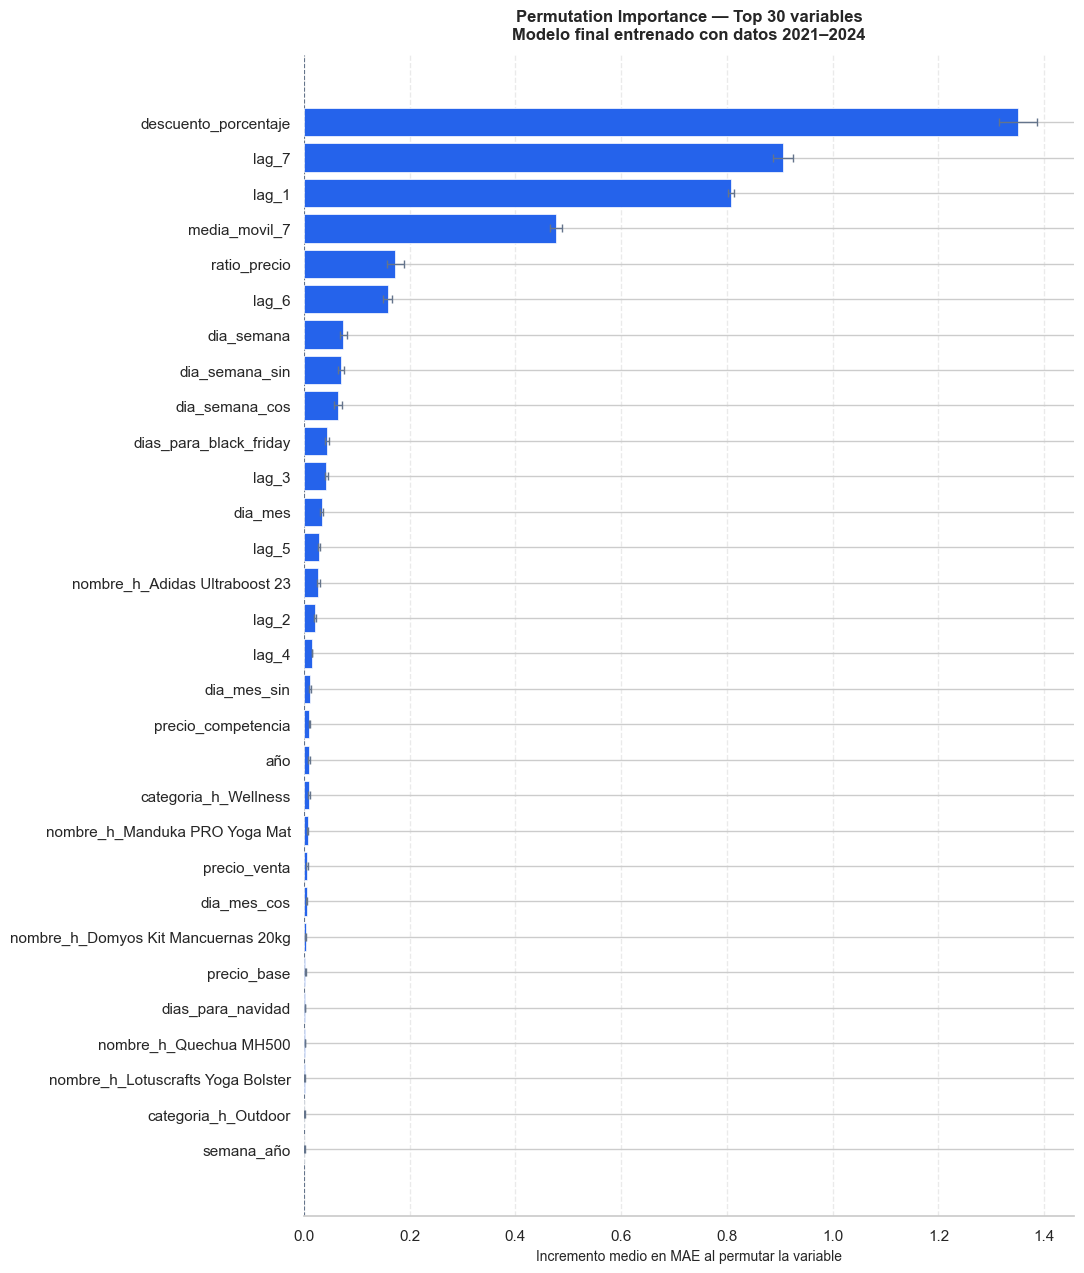

Modelo guardado en : ../models/modelo_final.joblib
Verificación OK    : predicción de prueba = 7.161


In [28]:

# ============================================================
# PERMUTATION IMPORTANCE — MODELO FINAL
# ============================================================

# ── 1. Calcular permutation importance ───────────────────────────────────────
print("Calculando permutation importance… (puede tardar unos segundos)")

perm = sklearn.inspection.permutation_importance(
    model_final, X_full, y_full,
    n_repeats    = 10,
    scoring      = "neg_mean_absolute_error",
    random_state = 42,
    n_jobs       = -1,
)

importancia_df = (
    pd.DataFrame({
        "feature"    : feature_cols,
        "importancia": perm.importances_mean,
        "std"        : perm.importances_std,
    })
    .sort_values("importancia", ascending=False)
    .reset_index(drop=True)
)

TOP_N = 30
top_df = importancia_df.head(TOP_N)

print(f"\nTop {TOP_N} variables por permutation importance (de {len(feature_cols)} totales)")
print("─" * 55)
print(top_df[["feature", "importancia", "std"]].to_string(index=False))

# ── 2. Gráfico de barras horizontales ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, TOP_N * 0.38 + 1.5))

plot_df = top_df.iloc[::-1]   # invertir para que la más importante quede arriba

colores = [
    "#2563EB" if v > 0 else "#94A3B8"
    for v in plot_df["importancia"]
]

ax.barh(
    plot_df["feature"], plot_df["importancia"],
    xerr      = plot_df["std"],
    color     = colores,
    edgecolor = "white",
    linewidth = 0.5,
    capsize   = 3,
    error_kw  = {"elinewidth": 1, "ecolor": "#64748B", "capthick": 1},
    zorder    = 3,
)

ax.axvline(0, color="#64748B", linewidth=0.8, linestyle="--")
ax.set_xlabel("Incremento medio en MAE al permutar la variable", fontsize=10)
ax.set_title(
    f"Permutation Importance — Top {TOP_N} variables\nModelo final entrenado con datos 2021–2024",
    fontsize=12, fontweight="bold", pad=12
)
ax.xaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

# ── 3. Guardar modelo final ───────────────────────────────────────────────────
models_dir  = "../models"
joblib.dump(model_final, f"{models_dir}/modelo_final.joblib")

print(f"Modelo guardado en : {models_dir}/modelo_final.joblib")

# Verificación
modelo_verificado = joblib.load(f"{models_dir}/modelo_final.joblib")
pred_test = modelo_verificado.predict(X_full.iloc[:1])
print(f"Verificación OK    : predicción de prueba = {pred_test[0]:.3f}")
